# Experiment 1 — Layer-wise speaker-change detection

Frozen WavLM Large representations are evaluated on VoxConverse using cosine-distance detectors and logistic probes. The study compares the 24 transformer layers at held-out speaker boundaries.


In [ ]:
from pathlib import Path

MODE = "pilot"
PERSISTENT_ROOT = Path("/content/drive/MyDrive/wavlm_layerwise_scd")
PRESETS = {
    "smoke": {"max_recordings": {"train": 5, "val": 2, "test": 2}, "max_audio_seconds": 60},
    "pilot": {"max_recordings": {"train": 150, "val": 33, "test": 33}, "max_audio_seconds": None},
}
assert MODE in PRESETS
CFG = {
    "seed": 2025, "device": "auto", "mode": MODE,
    "model_id": "microsoft/wavlm-large", "model_revision": "main",
    "annotation_revision": None,
    "mount_google_drive": True, "drive_mount_point": "/content/drive",
    "dataset_root": str(PERSISTENT_ROOT / "voxconverse"),
    "audio_root": "/content/drive/MyDrive/voxdata",
    "cache_dir": str(PERSISTENT_ROOT / "features"),
    "output_dir": str(PERSISTENT_ROOT / "results" / MODE),
    "hf_cache_dir": str(PERSISTENT_ROOT / "huggingface"),
    "legacy_dataset_root": "/content/voxconverse",
    "manual_audio_archives": [],
    "auto_download_audio": False,
    "audio_download_urls": {
        partition: [
            f"https://mm.kaist.ac.kr/datasets/voxconverse/data/voxconverse_{partition}_wav.zip",
            f"https://www.robots.ox.ac.uk/~vgg/data/voxconverse/data/voxconverse_{partition}_wav.zip",
        ] for partition in ("dev", "test")
    },
    "audio_archive_md5": {"dev": "2a6e07e7473d9841abb132554a698a36",
                          "test": "834558bbd9b1ffd2d4893181556ceddd"},
    **PRESETS[MODE],
    "sample_rate": 16000, "chunk_seconds": 12.0, "chunk_halo_seconds": 2.0,
    "context_seconds": 1.0, "candidate_stride": 0.10,
    "label_tolerance": 0.10, "boundary_tolerance": 0.25,
    "max_silence_gap": 0.20, "minimum_speech_fraction": 0.90,
    "batch_size": 1,
    "mixed_precision": True,
    "classifier_C": 1.0, "classifier_max_iter": 400,
    "max_train_candidates": 30000,
    "threshold_quantiles": 41, "peak_spacing_grid": [0.25, 0.50, 1.0],
    "bootstrap_replicates": 500,
    "cache_schema": 1,
}


## Environment and data access

Connect to VoxConverse audio and install the analysis dependencies.


In [8]:
import os
import shutil

def copy_file_once(source: Path, destination: Path) -> Path:
    source, destination = Path(source), Path(destination)
    if destination.exists():
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".partial")
    shutil.copy2(source, temporary)
    temporary.replace(destination)
    return destination

def initialize_storage(cfg):
    if cfg["mount_google_drive"]:
        try:
            from google.colab import drive
        except ImportError as error:
            raise RuntimeError("Run this configuration in Colab. For local use, set mount_google_drive=False "
                               "and change dataset_root, cache_dir, output_dir and hf_cache_dir to local paths.") from error
        drive.mount(cfg["drive_mount_point"])
        my_drive = Path(cfg["drive_mount_point"]) / "MyDrive"
        if not my_drive.is_dir():
            raise RuntimeError("Google Drive is not mounted. Authorize Drive and rerun; local storage is not used as a fallback.")
        for key in ("dataset_root", "cache_dir", "output_dir", "hf_cache_dir"):
            if not Path(cfg[key]).resolve().is_relative_to(my_drive.resolve()):
                raise ValueError(f"{key} must be under {my_drive} to persist across Colab runtimes")
    if cfg.get("audio_root") is not None:
        audio_root = Path(cfg["audio_root"])
        if not audio_root.is_dir():
            raise FileNotFoundError(f"Existing audio folder not found: {audio_root}. "
                                    "Check the voxdata folder location and edit CFG['audio_root']. "
                                    "The notebook will not create it or download audio.")
    folders = {key: Path(cfg[key]) for key in ("dataset_root", "cache_dir", "output_dir", "hf_cache_dir")}
    for folder in folders.values():
        folder.mkdir(parents=True, exist_ok=True)
    os.environ["HF_HOME"] = str(folders["hf_cache_dir"])
    os.environ["HF_HUB_CACHE"] = str(folders["hf_cache_dir"] / "hub")
    legacy = Path(cfg["legacy_dataset_root"])
    if cfg.get("audio_root") is None and legacy.is_dir() and legacy.resolve() != folders["dataset_root"].resolve():
        copied = 0
        for source in sorted(legacy.rglob("*")):
            if source.is_file() and source.suffix.lower() in {".zip", ".wav", ".rttm", ".json", ".md"}:
                destination = folders["dataset_root"] / source.relative_to(legacy)
                if not destination.exists():
                    print("Preserving existing local dataset file:", source.name)
                    copy_file_once(source, destination)
                    copied += 1
        print(f"Preserved {copied} files from {legacy}; future runtimes use {folders['dataset_root']}.")
    print("Persistent annotations and metadata:", folders["dataset_root"])
    if cfg.get("audio_root") is not None:
        print("Existing audio (read in place):", cfg["audio_root"])
    print("Persistent feature cache:", folders["cache_dir"])
    print("Persistent results:", folders["output_dir"])
    return folders["dataset_root"], folders["cache_dir"], folders["output_dir"]

DATA, CACHE, OUT = initialize_storage(CFG)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Persistent annotations and metadata: /content/drive/MyDrive/wavlm_layerwise_scd/voxconverse
Existing audio (read in place): /content/drive/MyDrive/voxdata
Persistent feature cache: /content/drive/MyDrive/wavlm_layerwise_scd/features
Persistent results: /content/drive/MyDrive/wavlm_layerwise_scd/results/pilot


In [9]:
import subprocess
import sys
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    "numpy>=1.26,<3", "soundfile==0.13.1", "requests>=2.32,<3", "tqdm>=4.66,<5",
])

0

In [10]:
import hashlib
import json
import math
import shutil
import warnings
import zipfile
import numpy as np
import requests
import soundfile as sf
from tqdm.auto import tqdm

def json_ready(value):
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [json_ready(v) for v in value]
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, np.generic):
        return json_ready(value.item())
    if isinstance(value, float) and not math.isfinite(value):
        return None
    if isinstance(value, Path):
        return str(value)
    return value

def save_json(path, value):
    path = Path(path)
    temporary = path.with_suffix(path.suffix + ".tmp")
    temporary.write_text(json.dumps(json_ready(value), indent=2, allow_nan=False))
    temporary.replace(path)

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

## VoxConverse corpus and annotations

Locate recordings, load corrected RTTM annotations, and create recording-level splits.


In [11]:
def verify_audio_archive(path: Path, expected_md5: str, source_url=None, known_digests=None):
    path = Path(path)
    marker = path.with_name(path.name + ".source.json")
    stat = path.stat()
    if known_digests is None and marker.exists():
        metadata = json.loads(marker.read_text())
        if (metadata.get("size_bytes") == stat.st_size and metadata.get("mtime_ns") == stat.st_mtime_ns
                and metadata.get("md5") == expected_md5 and metadata.get("sha256")):
            return metadata
    if known_digests is None:
        hashes = {"md5": hashlib.md5(usedforsecurity=False), "sha256": hashlib.sha256()}
        with open(path,"rb") as handle, tqdm(total=stat.st_size,unit="B",unit_scale=True,desc="Verify cached archive") as bar:
            for block in iter(lambda: handle.read(1024*1024),b""):
                for digest in hashes.values():
                    digest.update(block)
                bar.update(len(block))
        known_digests = {name:digest.hexdigest() for name,digest in hashes.items()}
    if known_digests["md5"] != expected_md5:
        raise ValueError(f"Archive MD5 mismatch for {path.name}: expected {expected_md5}, got {known_digests['md5']}")
    metadata = {"archive":path.name, "source_url":source_url,
                "checksum_source":"https://mm.kaist.ac.kr/datasets/voxconverse/",
                **known_digests, "size_bytes":stat.st_size, "mtime_ns":stat.st_mtime_ns}
    save_json(marker,metadata)
    return metadata

def download_file(url: str, destination: Path, expected_md5=None) -> Path:
    destination = Path(destination)
    if destination.exists() and zipfile.is_zipfile(destination):
        try:
            if expected_md5 is not None:
                verify_audio_archive(destination,expected_md5)
            print("Reusing cached archive:", destination)
            return destination
        except ValueError as error:
            warnings.warn(f"Replacing invalid cached archive: {error}")
    destination.parent.mkdir(parents=True, exist_ok=True)
    temporary = destination.with_suffix(destination.suffix + ".partial")
    hashes = {"md5": hashlib.md5(usedforsecurity=False), "sha256": hashlib.sha256()} if expected_md5 else {}
    try:
        with requests.get(url, stream=True, timeout=(20, 90)) as response:
            response.raise_for_status()
            total = int(response.headers.get("Content-Length", 0))
            if total and total * 1.1 > shutil.disk_usage(destination.parent).free:
                raise OSError(f"Insufficient disk for {total / 2**30:.1f} GiB download")
            with open(temporary, "wb") as handle, tqdm(total=total or None, unit="B", unit_scale=True, desc=destination.name) as bar:
                for block in response.iter_content(1024 * 1024):
                    if block:
                        handle.write(block)
                        for digest in hashes.values():
                            digest.update(block)
                        bar.update(len(block))
        if total and temporary.stat().st_size != total:
            raise OSError("Download size differs from Content-Length")
        if not zipfile.is_zipfile(temporary):
            raise ValueError("Server did not return a ZIP archive")
        digests = {name:digest.hexdigest() for name,digest in hashes.items()}
        if expected_md5 and digests["md5"] != expected_md5:
            raise ValueError(f"Downloaded archive MD5 mismatch: expected {expected_md5}, got {digests['md5']}")
        temporary.replace(destination)
        if expected_md5:
            verify_audio_archive(destination,expected_md5,source_url=url,known_digests=digests)
    except Exception:
        temporary.unlink(missing_ok=True)
        raise
    return destination

def prepare_annotations() -> tuple[Path, dict]:
    lock_path = DATA / "annotation_source.json"
    if CFG["annotation_revision"]:
        revision = CFG["annotation_revision"]
    elif lock_path.exists():
        revision = json.loads(lock_path.read_text())["commit"]
    else:
        response = requests.get("https://api.github.com/repos/joonson/voxconverse/commits/master", timeout=30)
        response.raise_for_status()
        revision = response.json()["sha"]
    if not (len(revision) == 40 and all(c in "0123456789abcdef" for c in revision.lower())):
        raise ValueError("annotation_revision must be a full Git commit hash")
    archive = download_file(f"https://codeload.github.com/joonson/voxconverse/zip/{revision}", DATA / f"annotations-{revision}.zip")
    root = DATA / f"annotations-{revision}"
    if not (root / "dev").exists():
        with zipfile.ZipFile(archive) as zf:
            readme = next(n for n in zf.namelist() if n.endswith("/README.md"))
            if "Version 0.3" not in zf.read(readme).decode():
                raise ValueError("Archive README does not identify corrected version 0.3")
            for member in zf.infolist():
                parts = Path(member.filename).parts
                if len(parts) == 3 and parts[1] in {"dev", "test"} and parts[2].endswith(".rttm"):
                    target = root / parts[1] / Path(parts[2]).name
                    target.parent.mkdir(parents=True, exist_ok=True)
                    target.write_bytes(zf.read(member))
    for partition in ("dev", "test"):
        if not list((root / partition).glob("*.rttm")):
            raise RuntimeError(f"Missing {partition} annotations in {root}")
    provenance = {"version": "0.3", "commit": revision, "archive_sha256": sha256_file(archive)}
    save_json(lock_path, provenance)
    return root, provenance

def make_split_manifest(dev_ids, test_ids, cfg):
    rng = np.random.default_rng(cfg["seed"])
    dev_ids = rng.permutation(sorted(dev_ids)).tolist()
    official_test = rng.permutation(sorted(test_ids)).tolist()
    counts = cfg["max_recordings"]
    ntrain, nval, ntest = (counts[k] for k in ("train", "val", "test"))
    required = ntrain + nval + (ntest if cfg["mode"] != "full" else 0)
    if len(dev_ids) < required or (cfg["mode"] == "full" and len(official_test) < ntest):
        raise ValueError("Requested more recordings than available; lower max_recordings.")
    splits = {"train": dev_ids[:ntrain], "val": dev_ids[ntrain:ntrain+nval],
              "test": official_test[:ntest] if cfg["mode"] == "full" else dev_ids[ntrain+nval:required]}
    assert all(len(v) > 0 for v in splits.values())
    assert not (set(splits["train"]) & set(splits["val"]) or
                set(splits["train"]) & set(splits["test"]) or
                set(splits["val"]) & set(splits["test"]))
    return {"protocol": "official-test" if cfg["mode"] == "full" else "development-three-way-pilot",
            "seed": cfg["seed"], "mode": cfg["mode"], "splits": splits,
            "source_partition": {rid: ("test" if split == "test" and cfg["mode"] == "full" else "dev")
                                 for split, ids in splits.items() for rid in ids}}

def audio_index(audio_root):
    found = {}
    for path in sorted(Path(audio_root).rglob("*")):
        if path.is_file() and path.suffix.lower() == ".wav":
            if path.stem in found:
                raise ValueError(f"Duplicate WAV ID {path.stem}: {found[path.stem]} and {path}")
            found[path.stem] = path
    return found

def extract_selected_wavs(archive, wanted):
    if not wanted:
        return
    with zipfile.ZipFile(archive) as zf:
        for member in tqdm(zf.infolist(), desc="Scan/extract WAV archive", leave=False):
            name = Path(member.filename)
            if name.suffix.lower() == ".wav" and name.stem in wanted:
                destination = DATA / "audio" / f"{name.stem}.wav"
                destination.parent.mkdir(parents=True, exist_ok=True)
                if not destination.exists():
                    temporary = destination.with_suffix(".partial")
                    with zf.open(member) as source, open(temporary, "wb") as target:
                        shutil.copyfileobj(source, target)
                    sf.info(temporary)
                    temporary.replace(destination)

def prepare_audio(manifest):
    wanted = {rid for ids in manifest["splits"].values() for rid in ids}
    if CFG.get("audio_root") is not None:
        root = Path(CFG["audio_root"])
        if not root.is_dir():
            raise FileNotFoundError(f"Existing audio folder not found: {root}. Edit CFG['audio_root']; no audio will be downloaded.")
        found = audio_index(root)
        print(f"Found {len(found)} existing WAV files in {root}; selected {len(wanted)} recordings.")
        missing = wanted - found.keys()
        if missing:
            needs_test = any(manifest["source_partition"][rid] == "test" for rid in missing)
            advice = (" Full mode needs official test audio in addition to the 216 development files; "
                      "use pilot/smoke with the development set or add the test files under audio_root.") if needs_test else ""
            raise RuntimeError(f"Missing {len(missing)} selected recording IDs in {root}: {sorted(missing)[:12]}. "
                               "Check audio_root and original filenames. No audio downloads are attempted." + advice)
        selected = {rid:found[rid] for rid in sorted(wanted)}
        for rid,path in selected.items():
            info = sf.info(path)
            if info.frames <= 0 or info.samplerate <= 0:
                raise ValueError(f"Invalid audio: {path}")
        print("Using existing Drive audio directly; audio downloads and copies are disabled.")
        return selected
    found = audio_index(DATA / "audio")
    if wanted <= found.keys():
        print(f"Reusing all {len(wanted)} selected WAVs from {DATA / 'audio'}")
    partitions = sorted({manifest["source_partition"][rid] for rid in wanted})
    cached_archives = sorted((DATA / "manual_archives").glob("*.zip"))
    automatic_archives = {DATA / f"voxconverse_{partition}_wav.zip":partition for partition in partitions}
    cached_archives += list(automatic_archives)
    for archive in cached_archives:
        if wanted <= found.keys():
            break
        if not archive.is_file():
            continue
        if not zipfile.is_zipfile(archive):
            warnings.warn(f"Ignoring incomplete or invalid cached archive: {archive}")
            continue
        if archive in automatic_archives:
            try:
                verify_audio_archive(archive,CFG["audio_archive_md5"][automatic_archives[archive]])
            except ValueError as error:
                warnings.warn(f"Skipping invalid cached audio archive: {error}")
                continue
        print("Extracting missing WAVs from saved archive:", archive)
        extract_selected_wavs(archive, wanted - found.keys())
        found = audio_index(DATA / "audio")
    for archive in CFG["manual_audio_archives"]:
        if wanted <= found.keys():
            break
        source = Path(archive)
        if not source.is_file():
            warnings.warn(f"Upload path no longer exists: {source}; checking saved files and official downloads")
            continue
        archive = copy_file_once(source, DATA / "manual_archives" / source.name)
        print("Preserved uploaded archive:", archive)
        extract_selected_wavs(archive, wanted - found.keys())
        found = audio_index(DATA / "audio")
    missing = wanted - found.keys()
    failures = []
    if missing and CFG["auto_download_audio"]:
        for partition in sorted({manifest["source_partition"][rid] for rid in missing}):
            for url in CFG["audio_download_urls"][partition]:
                print(f"Trying {partition} audio source: {url}")
                try:
                    archive = download_file(url, DATA / f"voxconverse_{partition}_wav.zip",
                                            expected_md5=CFG["audio_archive_md5"][partition])
                    extract_selected_wavs(archive, missing)
                    print(f"Downloaded and verified {partition} VoxConverse audio from {url}")
                    break
                except (requests.RequestException, OSError, ValueError, zipfile.BadZipFile) as error:
                    detail = f"{partition}: {url}: {type(error).__name__}: {error}"
                    print("Audio source failed; trying the next configured source:", detail)
                    failures.append(detail)
        found = audio_index(DATA / "audio")
        missing = wanted - found.keys()
    if missing:
        raise RuntimeError(
            f"Missing {len(missing)} real VoxConverse WAVs (examples: {sorted(missing)[:8]}). "
            "All configured public sources failed or lacked the requested files. Upload a real VoxConverse WAV archive "
            "once and set CFG['manual_audio_archives'], or place original WAVs under dataset_root/audio/ on Drive. "
            "Rerun this section after supplying audio. No alternative audio is used. " + " | ".join(failures))
    for rid in wanted:
        info = sf.info(found[rid])
        if info.frames <= 0 or info.samplerate <= 0:
            raise ValueError(f"Invalid audio: {found[rid]}")
    return {rid: found[rid] for rid in sorted(wanted)}

In [12]:
ANN_ROOT, ANN_SOURCE = prepare_annotations()
MANIFEST = make_split_manifest(
    [p.stem for p in (ANN_ROOT / "dev").glob("*.rttm")],
    [p.stem for p in (ANN_ROOT / "test").glob("*.rttm")], CFG)
MANIFEST["annotation_source"] = ANN_SOURCE
save_json(OUT / "split_manifest.json", MANIFEST)
AUDIO_PATHS = prepare_audio(MANIFEST)
AUDIO_SOURCES = [] if CFG.get("audio_root") is not None else [
    json.loads(path.read_text()) for path in sorted(DATA.glob("voxconverse_*_wav.zip.source.json"))]
save_json(OUT / "audio_download_sources.json", AUDIO_SOURCES)
save_json(OUT / "audio_input_manifest.json", {
    "source_type":"existing-audio-directory" if CFG.get("audio_root") is not None else "managed-audio-cache",
    "audio_root": CFG.get("audio_root") or str(DATA / "audio"),
    "selected_recordings":len(AUDIO_PATHS), "paths":AUDIO_PATHS})
print("Annotation source:", ANN_SOURCE)
print({split: len(ids) for split, ids in MANIFEST["splits"].items()})
print("Audio and annotations ready before WavLM setup. New runtimes reuse these paths.")

Reusing cached archive: /content/drive/MyDrive/wavlm_layerwise_scd/voxconverse/annotations-24bf60be297701cd7e4ef18550c6d390c1b87365.zip
Found 216 existing WAV files in /content/drive/MyDrive/voxdata; selected 216 recordings.
Using existing Drive audio directly; audio downloads and copies are disabled.
Annotation source: {'version': '0.3', 'commit': '24bf60be297701cd7e4ef18550c6d390c1b87365', 'archive_sha256': 'c340d2cd9da2f19eff8a3adc55b0818ec45cd0770ef72c6926c4de6efe9e9a1d'}
{'train': 150, 'val': 33, 'test': 33}
Audio and annotations ready before WavLM setup. New runtimes reuse these paths.


## Model dependencies

Initialize the libraries used for WavLM feature extraction.


In [13]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "--quiet",
    "transformers==4.57.6", "huggingface-hub>=0.34,<1.0",
    "numpy>=1.26,<3", "pandas>=2.2,<3", "scipy>=1.13,<2",
    "scikit-learn==1.6.1", "matplotlib>=3.8,<4",
    "librosa==0.11.0", "soundfile==0.13.1", "tqdm>=4.66,<5",
    "requests>=2.32,<3", "joblib>=1.4,<2", "nbformat>=5.10,<6",
])

0

In [14]:
import os
os.environ["USE_TF"] = "0"
os.environ["USE_FLAX"] = "0"
import contextlib
import hashlib
import importlib.metadata
import json
import math
import random
import shutil
import warnings
import zipfile
from collections import Counter, defaultdict
from dataclasses import dataclass

import joblib
import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy.signal
import soundfile as sf
import torch
from huggingface_hub import model_info
from IPython.display import Audio, Markdown, display
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, confusion_matrix
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
from transformers import Wav2Vec2FeatureExtractor, WavLMModel

random.seed(CFG["seed"])
np.random.seed(CFG["seed"])
torch.manual_seed(CFG["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(CFG["seed"])
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu") if CFG["device"] == "auto" else torch.device(CFG["device"])
if DEVICE.type == "cuda" and not torch.cuda.is_available():
    raise RuntimeError("CUDA requested but unavailable. Select a Colab GPU runtime.")
assert CFG["batch_size"] == 1, "Use batch_size=1 for exact unpadded frame timing."
assert CFG["context_seconds"] > 0 and CFG["candidate_stride"] > 0
assert CFG["sample_rate"] == 16000, "This checkpoint expects 16 kHz audio."
assert 0 < CFG["minimum_speech_fraction"] <= 1 and CFG["max_silence_gap"] >= 0
assert CFG["max_train_candidates"] > 0 and CFG["bootstrap_replicates"] > 0
assert CFG["threshold_quantiles"] >= 2 and CFG["classifier_max_iter"] > 0 and CFG["classifier_C"] > 0
assert CFG["label_tolerance"] >= CFG["candidate_stride"] / 2
assert CFG["chunk_halo_seconds"] >= CFG["context_seconds"] + 0.04
assert CFG["chunk_seconds"] > 2 * CFG["chunk_halo_seconds"]
assert CFG["boundary_tolerance"] > 0 and min(CFG["peak_spacing_grid"]) > 0
DATA = Path(CFG["dataset_root"])
CACHE = Path(CFG["cache_dir"])
OUT = Path(CFG["output_dir"])
for folder in (DATA, CACHE, OUT):
    folder.mkdir(parents=True, exist_ok=True)

VERSIONS = {name: importlib.metadata.version(name) for name in [
    "torch", "transformers", "huggingface-hub", "numpy", "pandas", "scipy",
    "scikit-learn", "matplotlib", "librosa", "soundfile", "tqdm", "requests", "joblib",
]}
print("Python", sys.version, "\nVersions:", VERSIONS)
print("Device:", DEVICE, "CUDA:", torch.cuda.is_available())
if DEVICE.type == "cuda":
    free, total = torch.cuda.mem_get_info(DEVICE)
    print(torch.cuda.get_device_name(DEVICE), f"free/total GPU GiB: {free/2**30:.1f}/{total/2**30:.1f}")
else:
    warnings.warn("No CUDA: CPU extraction is supported but slow; use smoke for debugging.")
print("Paths:", DATA, CACHE, OUT)
print(f"Local free disk: {shutil.disk_usage(CACHE).free / 2**30:.1f} GiB")
save_json(OUT / "environment.json", {"python": sys.version, "packages": VERSIONS, "device": str(DEVICE)})
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 220, "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})

Python 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0] 
Versions: {'torch': '2.14.1+cu130', 'transformers': '4.57.6', 'huggingface-hub': '0.36.2', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'librosa': '0.11.0', 'soundfile': '0.13.1', 'tqdm': '4.67.3', 'requests': '2.32.4', 'joblib': '1.6.0'}
Device: cuda CUDA: True
NVIDIA A100-SXM4-80GB free/total GPU GiB: 78.8/79.3
Paths: /content/drive/MyDrive/wavlm_layerwise_scd/voxconverse /content/drive/MyDrive/wavlm_layerwise_scd/features /content/drive/MyDrive/wavlm_layerwise_scd/results/pilot
Local free disk: 208.4 GiB


## Speaker-change references

Parse RTTM turns and derive clean boundaries and oracle evaluation regions.


In [15]:
@dataclass(frozen=True)
class Turn:
    recording: str
    start: float
    end: float
    speaker: str

def parse_rttm_text(text: str, expected_id=None) -> list[Turn]:
    turns = []
    for line_number, line in enumerate(text.splitlines(), 1):
        if not line.strip() or line.lstrip().startswith("#"):
            continue
        fields = line.split()
        if fields[0] != "SPEAKER":
            continue
        if len(fields) < 9:
            raise ValueError(f"Malformed RTTM line {line_number}: {line}")
        rid, channel, speaker = fields[1], fields[2], fields[7]
        start, duration = float(fields[3]), float(fields[4])
        if not np.isfinite([start, duration]).all() or start < 0 or duration <= 0:
            raise ValueError(f"Invalid RTTM timing at line {line_number}")
        if channel != "1":
            raise ValueError("This notebook expects the mono VoxConverse channel 1")
        if expected_id is not None and rid != expected_id:
            raise ValueError(f"RTTM recording mismatch: {rid} != {expected_id}")
        turns.append(Turn(rid, start, start + duration, speaker))
    return sorted(turns, key=lambda turn: (turn.start, turn.end, turn.speaker))

def active_intervals(turns: list[Turn], duration: float):
    events = defaultdict(list)
    events[0.0]; events[duration]
    for turn in turns:
        a, b = max(0.0, turn.start), min(duration, turn.end)
        if b > a:
            events[a].append((turn.speaker, 1))
            events[b].append((turn.speaker, -1))
    times = sorted(events)
    active = Counter()
    spans = []
    for a, b in zip(times[:-1], times[1:]):
        for speaker, delta in events[a]:
            active[speaker] += delta
        speakers = tuple(sorted(s for s, n in active.items() if n > 0))
        if spans and spans[-1][2] == speakers:
            spans[-1] = (spans[-1][0], b, speakers)
        else:
            spans.append((a, b, speakers))
    return spans

def clean_change_boundaries(spans, max_gap: float):
    boundaries = []
    for index, (a, b, speakers) in enumerate(spans):
        if len(speakers) != 1 or index + 1 >= len(spans):
            continue
        j = index + 1
        if not spans[j][2]:
            if spans[j][1] - spans[j][0] > max_gap + 1e-8:
                continue
            j += 1
        if j < len(spans):
            c, d, following = spans[j]
            if len(following) == 1 and speakers != following:
                boundaries.append((b + c) / 2)
    return np.array(sorted(set(boundaries)), dtype=np.float64)

def context_properties(spans, t: float, context: float):
    left, right = t - context, t + context
    speech, longest_gap, overlap = 0.0, 0.0, False
    identities = set()
    for a, b, speakers in spans:
        width = min(b, right) - max(a, left)
        if width <= 0:
            continue
        if len(speakers) > 1:
            overlap = True
        if speakers:
            speech += width
            identities.update(speakers)
        else:
            longest_gap = max(longest_gap, width)
    return speech / (2 * context), longest_gap, overlap, identities

def merge_intervals(intervals):
    merged = []
    for a, b in sorted(intervals):
        if merged and a <= merged[-1][1] + 1e-8:
            merged[-1] = (merged[-1][0], max(b, merged[-1][1]))
        else:
            merged.append((a, b))
    return merged

def make_candidates(spans, raw_boundaries, duration: float, cfg):
    context, stride = cfg["context_seconds"], cfg["candidate_stride"]
    times, identities = [], []
    # Integer grid indices avoid accumulated floating-point offsets.
    for index in range(math.ceil(context / stride), math.floor((duration-context) / stride) + 1):
        t = round(index * stride, 9)
        fraction, gap, overlap, speakers = context_properties(spans, t, context)
        if not overlap and fraction >= cfg["minimum_speech_fraction"] - 1e-8 and gap <= cfg["max_silence_gap"] + 1e-8:
            times.append(t)
            identities.append(speakers)
    times = np.asarray(times, dtype=np.float64)
    exposure = merge_intervals([(max(0, t-stride/2), min(duration, t+stride/2)) for t in times])
    references = np.asarray([b for b in raw_boundaries if any(a-1e-8 <= b <= z+1e-8 for a, z in exposure)], dtype=np.float64)
    labels = np.full(len(times), -1, dtype=np.int8)
    for index, (t, speakers) in enumerate(zip(times, identities)):
        if len(references) and np.min(np.abs(references-t)) <= cfg["label_tolerance"] + 1e-8:
            labels[index] = 1
        elif len(speakers) == 1:
            labels[index] = 0
    return times, labels, references, exposure

def load_audio(path, max_seconds=None, target_sr=16000):
    info = sf.info(path)
    frames = info.frames if max_seconds is None else min(info.frames, round(max_seconds * info.samplerate))
    waveform, sr = sf.read(path, frames=frames, dtype="float32", always_2d=True)
    waveform = waveform.mean(axis=1)
    if sr != target_sr:
        waveform = librosa.resample(waveform, orig_sr=sr, target_sr=target_sr)
    if not len(waveform) or not np.isfinite(waveform).all():
        raise ValueError(f"Empty or non-finite audio: {path}")
    return np.ascontiguousarray(waveform, dtype=np.float32)

In [16]:
RECORDS = {}
for split, ids in MANIFEST["splits"].items():
    for rid in tqdm(ids, desc=f"Census {split}"):
        info = sf.info(AUDIO_PATHS[rid])
        duration = info.duration if CFG["max_audio_seconds"] is None else min(info.duration, CFG["max_audio_seconds"])
        rttm = ANN_ROOT / MANIFEST["source_partition"][rid] / f"{rid}.rttm"
        turns = parse_rttm_text(rttm.read_text(), rid)
        if not turns:
            warnings.warn(f"{rid}: empty annotation; no controlled examples possible")
        spans = active_intervals(turns, duration)
        raw = clean_change_boundaries(spans, CFG["max_silence_gap"])
        times, labels, refs, exposure = make_candidates(spans, raw, duration, CFG)
        RECORDS[rid] = dict(id=rid, split=split, path=AUDIO_PATHS[rid], duration=duration,
                            turns=turns, spans=spans, raw_refs=raw, times=times, labels=labels,
                            refs=refs, exposure=exposure, exposure_seconds=sum(b-a for a,b in exposure),
                            rttm_sha256=sha256_file(rttm))
CENSUS = pd.DataFrame([{
    "recording": rid, "split": r["split"], "seconds": r["duration"],
    "oracle_seconds": r["exposure_seconds"], "clean_changes": len(r["raw_refs"]),
    "evaluated_changes": len(r["refs"]), "excluded_changes": len(r["raw_refs"])-len(r["refs"]),
    "candidates": len(r["times"]), "positive_candidates": int((r["labels"] == 1).sum()),
    "negative_candidates": int((r["labels"] == 0).sum()), "ignored_candidates": int((r["labels"] < 0).sum()),
} for rid,r in RECORDS.items()])
summary = CENSUS.groupby("split").sum(numeric_only=True)
summary["recordings"] = CENSUS.groupby("split").size()
summary["hours"] = summary["seconds"] / 3600
summary["oracle_hours"] = summary["oracle_seconds"] / 3600
display(summary)
CENSUS.to_csv(OUT / "dataset_census.csv", index=False)
save_json(OUT / "dataset_summary.json", {"mode": MODE, "splits": summary.reset_index().to_dict("records")})
for split in ("train", "val", "test"):
    subset = CENSUS[CENSUS.split == split]
    if not subset.candidates.sum():
        raise RuntimeError(f"No oracle-valid {split} candidates. Increase recordings/duration and rerun.")
    if not subset.evaluated_changes.sum():
        warnings.warn(f"{split}: zero evaluated changes. Metrics will be flagged; increase sample for research.")
estimated_gib = CENSUS.candidates.sum() * 24 * 1025 * 2 / 2**30
print(f"Derived feature cache estimate: {estimated_gib:.2f} GiB plus audio/model and temporary files")
if estimated_gib * 1.2 > shutil.disk_usage(CACHE).free / 2**30:
    raise OSError("Not enough free cache storage. Reduce duration/counts or use mounted storage.")

Census train:   0%|          | 0/150 [00:00<?, ?it/s]

Census val:   0%|          | 0/33 [00:00<?, ?it/s]

Census test:   0%|          | 0/33 [00:00<?, ?it/s]

,seconds,oracle_seconds,clean_changes,evaluated_changes,excluded_changes,candidates,positive_candidates,negative_candidates,ignored_candidates,recordings,hours,oracle_hours
split,,,,,,,,,,,,
test,9779.195250,7433.2,173,137,36,74332,303,71749,2280,33,2.716443,2.064778
train,51477.226187,39992.3,775,604,171,399923,1323,388678,9922,150,14.299229,11.108972
val,11811.832062,8816.3,191,155,36,88163,348,85299,2516,33,3.281064,2.448972


Derived feature cache estimate: 25.77 GiB plus audio/model and temporary files


## Visualize annotated speech

Display speaker turns and eligible reference boundaries.


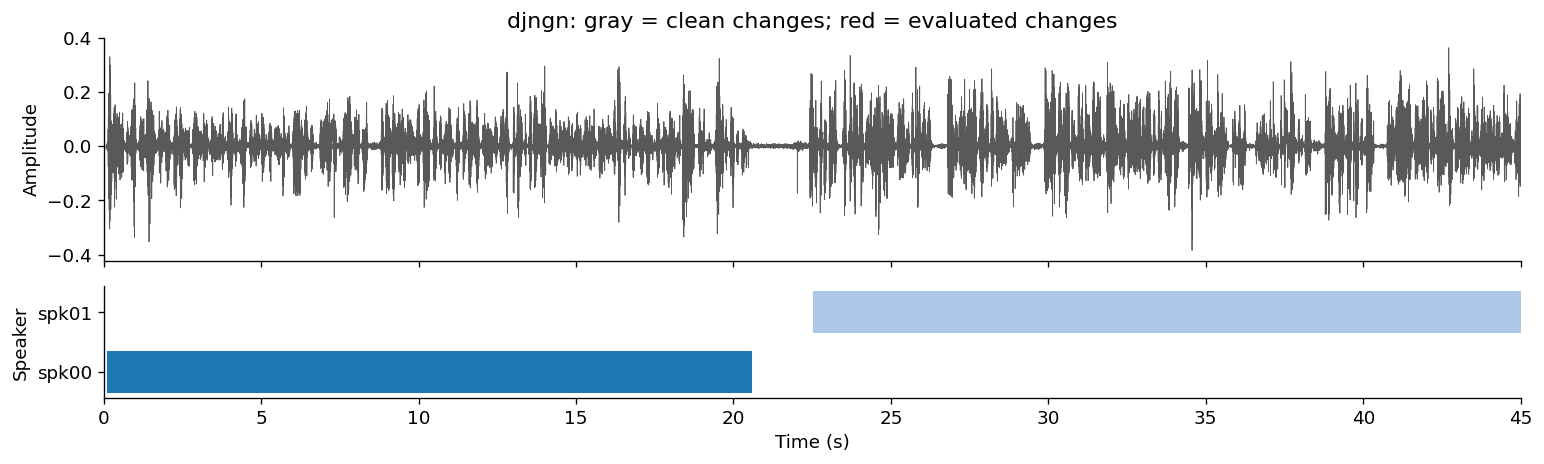

In [17]:
def plot_turns(record, seconds=45):
    y = load_audio(record["path"], min(record["duration"], seconds), CFG["sample_rate"])
    duration = len(y) / CFG["sample_rate"]
    fig, axes = plt.subplots(2, 1, figsize=(13, 4), sharex=True, gridspec_kw={"height_ratios": [2, 1]})
    step = max(1, len(y) // 30000)
    axes[0].plot(np.arange(0,len(y),step)/CFG["sample_rate"], y[::step], color="0.35", lw=.5)
    speakers = sorted({t.speaker for t in record["turns"]})
    for turn in record["turns"]:
        if turn.start < duration:
            row = speakers.index(turn.speaker)
            axes[1].broken_barh([(turn.start, min(turn.end,duration)-turn.start)], (row-.35,.7),
                                facecolors=plt.get_cmap("tab20")(row % 20))
    for ax in axes:
        for b in record["raw_refs"]:
            if b <= duration:
                ax.axvline(b, color="0.7", ls=":", lw=1)
        for b in record["refs"]:
            if b <= duration:
                ax.axvline(b, color="tab:red", ls="--", lw=1)
    axes[0].set(title=f"{record['id']}: gray = clean changes; red = evaluated changes", ylabel="Amplitude")
    axes[1].set(yticks=range(len(speakers)), yticklabels=speakers, xlabel="Time (s)", ylabel="Speaker", xlim=(0,duration))
    fig.tight_layout()
    return fig

EXAMPLE_ID = MANIFEST["splits"]["train"][0]
plot_turns(RECORDS[EXAMPLE_ID])
plt.show()

## Frozen WavLM Large

Load the checkpoint and expose all 24 transformer hidden states.


In [18]:
model_lock = CACHE / "model_source.json"
if CFG["model_revision"] == "main" and model_lock.exists():
    MODEL_COMMIT = json.loads(model_lock.read_text())[CFG["model_id"]]
else:
    MODEL_COMMIT = model_info(CFG["model_id"], revision=CFG["model_revision"]).sha
save_json(model_lock, {CFG["model_id"]: MODEL_COMMIT})
processor = Wav2Vec2FeatureExtractor.from_pretrained(CFG["model_id"], revision=MODEL_COMMIT)
model = WavLMModel.from_pretrained(CFG["model_id"], revision=MODEL_COMMIT).to(DEVICE)
model.requires_grad_(False)
model.eval()
assert model.config.num_hidden_layers == 24 and model.config.hidden_size == 1024
assert not any(p.requires_grad for p in model.parameters())
AMP_DTYPE = torch.bfloat16 if DEVICE.type == "cuda" and torch.cuda.is_bf16_supported() else torch.float16

def inference_context():
    return torch.autocast(device_type="cuda", dtype=AMP_DTYPE) if DEVICE.type == "cuda" and CFG["mixed_precision"] else contextlib.nullcontext()

def transformer_hidden_states(output, num_layers=24, hidden_size=1024):
    states = output.hidden_states
    if states is None or len(states) != num_layers + 1:
        raise ValueError("Expected initial representation plus every transformer layer")
    layers = states[1:]
    assert len(layers) == num_layers
    assert all(h.ndim == 3 and h.shape[-1] == hidden_size for h in layers)
    return layers

sample = load_audio(RECORDS[EXAMPLE_ID]["path"], min(4, RECORDS[EXAMPLE_ID]["duration"]), CFG["sample_rate"])
sample_inputs = processor(sample, sampling_rate=CFG["sample_rate"], return_tensors="pt")["input_values"].to(DEVICE)
with torch.inference_mode(), inference_context():
    sample_output = model(sample_inputs, output_hidden_states=True)
    for index, hidden in enumerate(sample_output.hidden_states):
        print("initial (not a transformer layer)" if index == 0 else f"transformer layer {index:02d}", tuple(hidden.shape))
    transformer_hidden_states(sample_output)
del sample_output, sample_inputs, sample
save_json(OUT / "experiment_config.json", {**CFG, "resolved_device": str(DEVICE), "model_commit": MODEL_COMMIT,
                                           "annotation_source": ANN_SOURCE, "versions": VERSIONS})

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


initial (not a transformer layer) (1, 199, 1024)
transformer layer 01 (1, 199, 1024)
transformer layer 02 (1, 199, 1024)
transformer layer 03 (1, 199, 1024)
transformer layer 04 (1, 199, 1024)
transformer layer 05 (1, 199, 1024)
transformer layer 06 (1, 199, 1024)
transformer layer 07 (1, 199, 1024)
transformer layer 08 (1, 199, 1024)
transformer layer 09 (1, 199, 1024)
transformer layer 10 (1, 199, 1024)
transformer layer 11 (1, 199, 1024)
transformer layer 12 (1, 199, 1024)
transformer layer 13 (1, 199, 1024)
transformer layer 14 (1, 199, 1024)
transformer layer 15 (1, 199, 1024)
transformer layer 16 (1, 199, 1024)
transformer layer 17 (1, 199, 1024)
transformer layer 18 (1, 199, 1024)
transformer layer 19 (1, 199, 1024)
transformer layer 20 (1, 199, 1024)
transformer layer 21 (1, 199, 1024)
transformer layer 22 (1, 199, 1024)
transformer layer 23 (1, 199, 1024)
transformer layer 24 (1, 199, 1024)


## Layer-wise feature extraction

Pool left/right context representations and cache boundary features.


In [19]:
def convolution_geometry(kernels, strides):
    receptive, jump = 1, 1
    for kernel, stride in zip(kernels, strides):
        receptive += (kernel - 1) * jump
        jump *= stride
    return receptive, jump

def frame_centers(frame_count, chunk_start_sample, kernels, strides, sample_rate):
    receptive, jump = convolution_geometry(kernels, strides)
    return (chunk_start_sample + (receptive-1)/2 + np.arange(frame_count)*jump) / sample_rate

def chunk_plan(num_samples, sample_rate, chunk_seconds, halo_seconds, jump):
    chunk = math.floor(chunk_seconds*sample_rate/jump)*jump
    halo = math.ceil(halo_seconds*sample_rate/jump)*jump
    core = chunk - 2*halo
    if core <= 0:
        raise ValueError("Chunk must be longer than twice its halo")
    for core_start in range(0, num_samples, core):
        core_end = min(num_samples, core_start+core)
        start, end = max(0, core_start-halo), min(num_samples, core_end+halo)
        assert start % jump == 0
        yield core_start/sample_rate, core_end/sample_rate, start, end

def pool_candidate_features(hidden_layers, centers, times, context):
    # Return [layers, candidates, hidden+1]; the last column is cosine similarity.
    if not len(times):
        return np.empty((len(hidden_layers), 0, hidden_layers[0].shape[-1]+1), np.float16)
    bounds = []
    for t in times:
        a, b, c = np.searchsorted(centers, [t-context, t, t+context], side="left")
        if not (0 <= a < b < c <= len(centers)):
            raise ValueError(f"Empty or misaligned pooling window at {t:.3f}s")
        bounds.append((a,b,c))
    bounds = np.asarray(bounds)
    result = np.empty((len(hidden_layers), len(times), hidden_layers[0].shape[-1]+1), np.float16)
    for layer, hidden in enumerate(hidden_layers):
        h = hidden[0].float()
        prefix = torch.cat([torch.zeros((1,h.shape[1]), device=h.device), h.cumsum(0)], dim=0)
        a,b,c = [torch.as_tensor(bounds[:,j], device=h.device) for j in range(3)]
        left = (prefix[b]-prefix[a])/(b-a).unsqueeze(1)
        right = (prefix[c]-prefix[b])/(c-b).unsqueeze(1)
        cosine = torch.nn.functional.cosine_similarity(left, right, dim=1, eps=1e-8).clamp(-1,1)
        features = torch.cat([(left-right).abs(), cosine[:,None]], dim=1)
        result[layer] = features.cpu().numpy().astype(np.float16)
    if not np.isfinite(result).all():
        raise FloatingPointError("Non-finite pooled features; disable mixed precision and retry")
    return result

def feature_fingerprint(record, waveform):
    settings = {key: CFG[key] for key in ["model_id", "sample_rate", "chunk_seconds", "chunk_halo_seconds",
                "context_seconds", "candidate_stride", "label_tolerance", "boundary_tolerance",
                "max_silence_gap", "minimum_speech_fraction", "mixed_precision", "cache_schema"]}
    payload = {"settings": settings, "model_commit": MODEL_COMMIT, "annotation": record["rttm_sha256"],
               "audio_sha256": hashlib.sha256(waveform.tobytes()).hexdigest(), "versions": VERSIONS,
               "device": str(DEVICE), "amp_dtype": str(AMP_DTYPE), "times": record["times"].tolist()}
    return hashlib.sha256(json.dumps(payload, sort_keys=True).encode()).hexdigest()

def extract_recording(record):
    waveform = load_audio(record["path"], record["duration"], CFG["sample_rate"])
    signature = feature_fingerprint(record, waveform)
    root = CACHE / signature[:20]
    root.mkdir(parents=True, exist_ok=True)
    feature_path, marker = root / f"{record['id']}.npy", root / f"{record['id']}.complete.json"
    shape = (24, len(record["times"]), 1025)
    if feature_path.exists() and marker.exists():
        metadata = json.loads(marker.read_text())
        cached = np.load(feature_path, mmap_mode="r", allow_pickle=False)
        if metadata["signature"] == signature and cached.shape == shape and cached.dtype == np.float16:
            return feature_path
    marker.unlink(missing_ok=True)
    if not len(record["times"]):
        np.save(feature_path, np.empty(shape, dtype=np.float16), allow_pickle=False)
        save_json(marker, {"signature": signature, "shape": shape})
        return feature_path
    temporary = feature_path.with_suffix(".partial.npy")
    features = np.lib.format.open_memmap(temporary, mode="w+", dtype=np.float16, shape=shape)
    assigned = np.zeros(len(record["times"]), dtype=np.int8)
    kernels, strides = model.config.conv_kernel, model.config.conv_stride
    _, jump = convolution_geometry(kernels, strides)
    plans = list(chunk_plan(len(waveform), CFG["sample_rate"], CFG["chunk_seconds"], CFG["chunk_halo_seconds"], jump))
    for core_a, core_b, start, end in tqdm(plans, desc=record["id"], leave=False):
        indexes = np.flatnonzero((record["times"] >= core_a) & (record["times"] < core_b))
        if not len(indexes):
            continue
        inputs = processor(waveform[start:end], sampling_rate=CFG["sample_rate"], return_tensors="pt")["input_values"].to(DEVICE)
        try:
            with torch.inference_mode(), inference_context():
                output = model(inputs, output_hidden_states=True)
                layers = transformer_hidden_states(output)
                centers = frame_centers(layers[0].shape[1], start, kernels, strides, CFG["sample_rate"])
                assert all(record["times"][indexes]-CFG["context_seconds"] >= start/CFG["sample_rate"]-1e-8)
                pooled = pool_candidate_features(layers, centers, record["times"][indexes], CFG["context_seconds"])
                features[:, indexes, :] = pooled
            assigned[indexes] += 1
            del output, layers, pooled, inputs
        except torch.cuda.OutOfMemoryError as error:
            raise RuntimeError("GPU OOM. Reduce chunk_seconds (keep >2*halo), then rerun extraction. "
                               "The cache signature will change; consider mixed_precision=True.") from error
    assert np.all(assigned == 1), "Every candidate must be pooled exactly once"
    features.flush()
    del features
    temporary.replace(feature_path)
    save_json(marker, {"signature": signature, "shape": shape, "dtype": "float16"})
    return feature_path

In [20]:
FEATURE_PATHS = {}
for rid, record in tqdm(RECORDS.items(), desc="Extract/resume recordings"):
    FEATURE_PATHS[rid] = extract_recording(record)
save_json(OUT / "feature_manifest.json", FEATURE_PATHS)
assert not model.training and not any(p.requires_grad for p in model.parameters())
print("Cached recordings:", len(FEATURE_PATHS), "(all 24 layers per forward pass)")
model.to("cpu")
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()

Extract/resume recordings:   0%|          | 0/216 [00:00<?, ?it/s]

zyffh:   0%|          | 0/32 [00:00<?, ?it/s]

pnyir:   0%|          | 0/59 [00:00<?, ?it/s]

ezsgk:   0%|          | 0/27 [00:00<?, ?it/s]

cmfyw:   0%|          | 0/61 [00:00<?, ?it/s]

yrsve:   0%|          | 0/74 [00:00<?, ?it/s]

... (191 outputs left out)

ehpau:   0%|          | 0/20 [00:00<?, ?it/s]

atgpi:   0%|          | 0/16 [00:00<?, ?it/s]

lknjp:   0%|          | 0/13 [00:00<?, ?it/s]

Cached recordings: 216 (all 24 layers per forward pass)


## Detection candidates

Build labeled training windows and cosine-difference features.


In [21]:
TRAIN_PAIRS = [(rid, int(i)) for rid in MANIFEST["splits"]["train"]
               for i in np.flatnonzero(RECORDS[rid]["labels"] >= 0)]
if not TRAIN_PAIRS:
    raise RuntimeError("No labeled training candidates; increase recordings or duration")
if len(TRAIN_PAIRS) > CFG["max_train_candidates"]:
    selected = np.random.default_rng(CFG["seed"]).choice(len(TRAIN_PAIRS), CFG["max_train_candidates"], replace=False)
    TRAIN_PAIRS = [TRAIN_PAIRS[i] for i in sorted(selected)]
Y_TRAIN = np.asarray([RECORDS[rid]["labels"][i] for rid,i in TRAIN_PAIRS], dtype=np.int8)
save_json(OUT / "training_examples.json", {"pairs": TRAIN_PAIRS, "class_counts": dict(Counter(Y_TRAIN.tolist()))})
print("Training candidates:", len(Y_TRAIN), "class counts:", dict(Counter(Y_TRAIN.tolist())))

def training_matrix(layer):
    x = np.empty((len(TRAIN_PAIRS), 1025), dtype=np.float32)
    positions = defaultdict(list)
    for row, (rid, index) in enumerate(TRAIN_PAIRS):
        positions[rid].append((row,index))
    for rid, pairs in positions.items():
        rows, indexes = np.asarray(pairs).T
        cached = np.load(FEATURE_PATHS[rid], mmap_mode="r", allow_pickle=False)
        x[rows] = cached[layer-1,indexes,:]
    return x

def layer_features(rid, layer):
    return np.asarray(np.load(FEATURE_PATHS[rid], mmap_mode="r", allow_pickle=False)[layer-1], dtype=np.float32)

Training candidates: 30000 class counts: {0: 29915, 1: 85}


## Logistic speaker-change probes

Fit an independent standardized classifier for each WavLM layer.


In [22]:
def fit_probe(x, y, cfg):
    if len(np.unique(y)) < 2:
        return {"constant": float(y[0]), "scaler": None, "classifier": None,
                "converged": False, "status": "single-class training; constant score"}
    scaler = StandardScaler()
    x = scaler.fit_transform(x)
    clf = LogisticRegression(C=cfg["classifier_C"], class_weight="balanced", solver="lbfgs",
                             max_iter=cfg["classifier_max_iter"], random_state=cfg["seed"])
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        clf.fit(x, y)
    converged = not any(issubclass(item.category, ConvergenceWarning) for item in caught)
    return {"constant": None, "scaler": scaler, "classifier": clf, "converged": converged,
            "status": "ok" if converged else "iteration limit; increase common budget"}

def probe_scores(probe, x):
    if not len(x):
        return np.empty(0, dtype=float)
    if probe["constant"] is not None:
        return np.full(len(x), probe["constant"])
    return probe["classifier"].predict_proba(probe["scaler"].transform(x))[:,1]

PROBE_PATHS = {}
TRAINING_STATUS = {}
for layer in tqdm(range(1,25), desc="Train 24 probes"):
    x = training_matrix(layer)
    probe = fit_probe(x, Y_TRAIN, CFG)
    path = OUT / f"logistic_layer_{layer:02d}.joblib"
    joblib.dump(probe, path)
    PROBE_PATHS[layer] = path
    TRAINING_STATUS[layer] = probe["status"]
    if probe["classifier"] is not None:
        np.savez(OUT / f"logistic_layer_{layer:02d}_parameters.npz",
                 mean=probe["scaler"].mean_, scale=probe["scaler"].scale_,
                 coef=probe["classifier"].coef_, intercept=probe["classifier"].intercept_,
                 classes=probe["classifier"].classes_)
    if probe["status"] != "ok":
        warnings.warn(f"Layer {layer}: {probe['status']}")
    del x, probe
save_json(OUT / "training_status.json", TRAINING_STATUS)

Train 24 probes:   0%|          | 0/24 [00:00<?, ?it/s]

## Boundary detection metrics

Choose thresholds on validation data and measure event F1 and candidate AP.


In [23]:
def precision_recall_f1(tp, fp, fn):
    precision = tp/(tp+fp) if tp+fp else 0.0
    recall = tp/(tp+fn) if tp+fn else 0.0
    f1 = 2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else 0.0
    return {"precision": precision, "recall": recall, "f1": f1}

def match_boundaries(predictions, references, tolerance):
    predictions, references = np.sort(np.asarray(predictions)), np.sort(np.asarray(references))
    i = j = 0
    matches, false_positives, misses = [], [], []
    while i < len(predictions) and j < len(references):
        p, r = float(predictions[i]), float(references[j])
        if p < r-tolerance-1e-8:
            false_positives.append(p); i += 1
        elif r < p-tolerance-1e-8:
            misses.append(r); j += 1
        else:
            matches.append((p,r)); i += 1; j += 1
    false_positives.extend(predictions[i:].tolist())
    misses.extend(references[j:].tolist())
    return matches, false_positives, misses

def detect_boundaries(times, scores, threshold, spacing):
    times, scores = np.asarray(times), np.asarray(scores)
    candidates = np.flatnonzero(scores >= threshold)
    # Stable deterministic ties: earlier timestamp first.
    order = candidates[np.lexsort((times[candidates], -scores[candidates]))]
    chosen = []
    suppressed = np.zeros(len(times), dtype=bool)
    for index in order:
        if suppressed[index]:
            continue
        chosen.append(index)
        left = np.searchsorted(times,times[index]-spacing+1e-8,side="right")
        right = np.searchsorted(times,times[index]+spacing-1e-8,side="left")
        suppressed[left:right] = True
    return np.sort(times[chosen]) if chosen else np.empty(0)

def counts_from_predictions(record, predictions, tolerance):
    matches, fp, fn = match_boundaries(predictions, record["refs"], tolerance)
    return {"tp": len(matches), "fp": len(fp), "fn": len(fn),
            "seconds": record["exposure_seconds"], "recording_seconds": record["duration"],
            "predictions": predictions, "matches": matches, "false_positives": fp, "misses": fn}

def event_counts(record, scores, threshold, spacing, tolerance):
    predictions = detect_boundaries(record["times"], scores, threshold, spacing)
    return counts_from_predictions(record,predictions,tolerance)

def aggregate_events(details):
    tp, fp, fn = (sum(d[k] for d in details) for k in ("tp", "fp", "fn"))
    seconds = sum(d["seconds"] for d in details)
    full_seconds = sum(d["recording_seconds"] for d in details)
    return {**precision_recall_f1(tp,fp,fn), "tp": tp, "fp": fp, "fn": fn,
            "false_detections_per_minute": 60*fp/seconds if seconds else np.nan,
            "false_detections_per_recording_minute": 60*fp/full_seconds if full_seconds else np.nan,
            "reference_count": tp+fn, "prediction_count": tp+fp, "exposure_minutes": seconds/60}

def candidate_metrics(labels, scores, threshold):
    keep = np.asarray(labels) >= 0
    labels, scores = np.asarray(labels)[keep], np.asarray(scores)[keep]
    if not len(labels):
        return {**precision_recall_f1(0,0,0), "pr_auc_ap": np.nan, "tn": 0, "fp": 0, "fn": 0, "tp": 0,
                "n": 0, "positives": 0}
    tn, fp, fn, tp = confusion_matrix(labels, scores >= threshold, labels=[0,1]).ravel()
    ap = average_precision_score(labels, scores) if np.any(labels == 1) else np.nan
    return {**precision_recall_f1(tp,fp,fn), "pr_auc_ap": float(ap), "tn": int(tn), "fp": int(fp),
            "fn": int(fn), "tp": int(tp), "n": len(labels), "positives": int(labels.sum())}

def select_detection_configuration(records, scores_by_id, cfg):
    if not sum(len(r["refs"]) for r in records.values()):
        return {"threshold": float("inf"), "spacing": max(cfg["peak_spacing_grid"]),
                "validation_event_f1": 0.0, "status": "zero validation references; no detections",
                "prediction_rule": "none"}
    values = np.concatenate([scores_by_id[rid] for rid in records])
    if not len(values):
        raise ValueError("No validation candidate scores")
    thresholds = np.unique(np.r_[np.nextafter(values.min(), -np.inf),
                                np.quantile(values,np.linspace(0,1,cfg["threshold_quantiles"])), np.inf])
    best_key, best = None, None
    for spacing in cfg["peak_spacing_grid"]:
        # NMS is score-ordered: removing lower-score candidates cannot change
        peaks = {rid: detect_boundaries(r["times"],scores_by_id[rid],-np.inf,spacing)
                 for rid,r in records.items()}
        peak_scores = {rid: scores_by_id[rid][np.searchsorted(records[rid]["times"],p)]
                       for rid,p in peaks.items()}
        for threshold in thresholds:
            details = [counts_from_predictions(r,peaks[rid][peak_scores[rid]>=threshold],cfg["boundary_tolerance"])
                       for rid,r in records.items()]
            metric = aggregate_events(details)
            key = (metric["f1"], -metric["fp"], float(threshold), spacing)
            if best_key is None or key > best_key:
                best_key = key
                best = {"threshold": float(threshold), "spacing": spacing,
                        "validation_event_f1": metric["f1"], "status": "validation selected",
                        "prediction_rule": "none" if np.isinf(threshold) else "score >= threshold"}
    return best

def score_layer(layer, ids):
    probe = joblib.load(PROBE_PATHS[layer])
    scores = {"cosine": {}, "logistic": {}}
    for rid in ids:
        x = layer_features(rid, layer)
        scores["cosine"][rid] = np.clip((1-x[:,-1])/2, 0, 1)
        scores["logistic"][rid] = probe_scores(probe, x)
    return scores

def bootstrap_f1(details, replicates, seed):
    if not details or not sum(d["tp"]+d["fn"] for d in details):
        return (np.nan,np.nan)
    counts = np.asarray([[d["tp"],d["fp"],d["fn"]] for d in details], dtype=float)
    rng = np.random.default_rng(seed)
    draws = rng.integers(0,len(counts),size=(replicates,len(counts)))
    totals = counts[draws].sum(axis=1)
    denominator = 2*totals[:,0]+totals[:,1]+totals[:,2]
    f1 = np.divide(2*totals[:,0], denominator, out=np.zeros(replicates), where=denominator>0)
    return tuple(np.quantile(f1,[.025,.975]))

In [24]:
DETECTION_CONFIGS = {}
val_records = {rid: RECORDS[rid] for rid in MANIFEST["splits"]["val"]}
for layer in tqdm(range(1,25), desc="Validation only: thresholds and peak spacing"):
    val_scores = score_layer(layer, MANIFEST["splits"]["val"])
    for method in ("cosine", "logistic"):
        DETECTION_CONFIGS[(method,layer)] = select_detection_configuration(val_records, val_scores[method], CFG)
save_json(OUT / "validation_selected_thresholds.json", [
    {"method": method, "layer": layer, **settings} for (method,layer), settings in DETECTION_CONFIGS.items()])
VALIDATION_BEST = {method: max(range(1,25), key=lambda layer: (
    DETECTION_CONFIGS[(method,layer)]["validation_event_f1"], -layer)) for method in ("cosine", "logistic")}
save_json(OUT / "validation_selected_layers.json", VALIDATION_BEST)
print("Frozen validation-selected layers:", VALIDATION_BEST)

rows, EVENT_DETAILS = [], {}
for layer in tqdm(range(1,25), desc="Final test evaluation; no tuning"):
    scores = score_layer(layer, MANIFEST["splits"]["test"])
    row = {"layer": layer, "training_status": TRAINING_STATUS[layer]}
    for method in ("cosine", "logistic"):
        settings = DETECTION_CONFIGS[(method,layer)]
        details = {rid: event_counts(RECORDS[rid], scores[method][rid], settings["threshold"], settings["spacing"], CFG["boundary_tolerance"])
                   for rid in MANIFEST["splits"]["test"]}
        EVENT_DETAILS[(method,layer)] = details
        event = aggregate_events(list(details.values()))
        labels = np.concatenate([RECORDS[rid]["labels"] for rid in MANIFEST["splits"]["test"]])
        all_scores = np.concatenate([scores[method][rid] for rid in MANIFEST["splits"]["test"]])
        candidate = candidate_metrics(labels, all_scores, settings["threshold"])
        low, high = bootstrap_f1(list(details.values()), CFG["bootstrap_replicates"], CFG["seed"])
        row.update({f"{method}_candidate_{k}": v for k,v in candidate.items()})
        row.update({f"{method}_event_{k}": v for k,v in event.items()})
        row.update({f"{method}_event_f1_ci_low": low, f"{method}_event_f1_ci_high": high,
                    f"{method}_validation_event_f1": settings["validation_event_f1"],
                    f"{method}_threshold": settings["threshold"], f"{method}_peak_spacing": settings["spacing"],
                    f"{method}_configuration_status": settings["status"]})
    rows.append(row)
RESULTS = pd.DataFrame(rows)
RESULTS.to_csv(OUT / "layerwise_results.csv", index=False)
save_json(OUT / "layerwise_results.json", {"config": CFG, "protocol": MANIFEST["protocol"], "results": RESULTS.to_dict("records")})
save_json(OUT / "event_details.json", [{"method": method, "layer": layer, "recordings": details}
                                       for (method,layer), details in EVENT_DETAILS.items()])
display(RESULTS.style.highlight_max(subset=["cosine_event_f1", "logistic_event_f1"], color="#d8efd3"))

Validation only: thresholds and peak spacing:   0%|          | 0/24 [00:00<?, ?it/s]

Frozen validation-selected layers: {'cosine': 10, 'logistic': 8}


Final test evaluation; no tuning:   0%|          | 0/24 [00:00<?, ?it/s]

,layer,training_status,cosine_candidate_precision,cosine_candidate_recall,cosine_candidate_f1,cosine_candidate_pr_auc_ap,cosine_candidate_tn,cosine_candidate_fp,cosine_candidate_fn,cosine_candidate_tp,cosine_candidate_n,cosine_candidate_positives,cosine_event_precision,cosine_event_recall,cosine_event_f1,cosine_event_tp,cosine_event_fp,cosine_event_fn,cosine_event_false_detections_per_minute,cosine_event_false_detections_per_recording_minute,cosine_event_reference_count,cosine_event_prediction_count,cosine_event_exposure_minutes,cosine_event_f1_ci_low,cosine_event_f1_ci_high,cosine_validation_event_f1,cosine_threshold,cosine_peak_spacing,cosine_configuration_status,logistic_candidate_precision,logistic_candidate_recall,logistic_candidate_f1,logistic_candidate_pr_auc_ap,logistic_candidate_tn,logistic_candidate_fp,logistic_candidate_fn,logistic_candidate_tp,logistic_candidate_n,logistic_candidate_positives,logistic_event_precision,logistic_event_recall,logistic_event_f1,logistic_event_tp,logistic_event_fp,logistic_event_fn,logistic_event_false_detections_per_minute,logistic_event_false_detections_per_recording_minute,logistic_event_reference_count,logistic_event_prediction_count,logistic_event_exposure_minutes,logistic_event_f1_ci_low,logistic_event_f1_ci_high,logistic_validation_event_f1,logistic_threshold,logistic_peak_spacing,logistic_configuration_status
0,1,ok,0.024990,0.214521,0.044766,0.019960,69213,2536,238,65,72052,303,0.042239,0.291971,0.073801,40,907,97,7.321208,5.564875,137,947,123.886667,0.041113,0.115818,0.088324,0.077881,0.500000,validation selected,0.044475,0.211221,0.073479,0.058470,70374,1375,239,64,72052,303,0.052566,0.306569,0.089744,42,757,95,6.110424,4.644554,137,799,123.886667,0.058212,0.125126,0.095469,0.004703,0.500000,validation selected
1,2,ok,0.044277,0.174917,0.070667,0.027325,70605,1144,250,53,72052,303,0.072727,0.233577,0.110919,32,408,105,3.293333,2.503273,137,440,123.886667,0.059688,0.169461,0.130966,0.130127,1.000000,validation selected,0.086743,0.349835,0.139016,0.157342,70633,1116,197,106,72052,303,0.082857,0.423358,0.138590,58,642,79,5.182156,3.938974,137,700,123.886667,0.101021,0.176651,0.173507,0.015378,0.500000,validation selected
2,3,ok,0.058594,0.247525,0.094757,0.039769,70544,1205,228,75,72052,303,0.096567,0.328467,0.149254,45,421,92,3.398267,2.583035,137,466,123.886667,0.092881,0.213810,0.152968,0.162109,1.000000,validation selected,0.126538,0.475248,0.199861,0.279204,70755,994,159,144,72052,303,0.121914,0.576642,0.201274,79,569,58,4.592907,3.491085,137,648,123.886667,0.144342,0.263126,0.206025,0.019929,0.500000,validation selected
3,4,ok,0.071843,0.326733,0.117787,0.049282,70470,1279,204,99,72052,303,0.120654,0.430657,0.188498,59,430,78,3.470914,2.638254,137,489,123.886667,0.121152,0.268574,0.183314,0.161621,1.000000,validation selected,0.184304,0.511551,0.270979,0.405715,71063,686,148,155,72052,303,0.168803,0.576642,0.261157,79,389,58,3.139967,2.386699,137,468,123.886667,0.201680,0.321317,0.247596,0.013389,1.000000,validation selected
4,5,ok,0.077206,0.346535,0.126278,0.050370,70494,1255,198,105,72052,303,0.115385,0.416058,0.180666,57,437,80,3.527418,2.681202,137,494,123.886667,0.114195,0.260610,0.191388,0.178711,1.000000,validation selected,0.205597,0.630363,0.310065,0.496834,71011,738,112,191,72052,303,0.160083,0.562044,0.249191,77,404,60,3.261045,2.478732,137,481,123.886667,0.175913,0.319011,0.274045,0.010219,1.000000,validation selected
5,6,ok,0.069191,0.349835,0.115531,0.047875,70323,1426,197,106,72052,303,0.103074,0.416058,0.165217,57,496,80,4.003659,3.043195,137,553,123.886667,0.097242,0.242269,0.195349,0.200195,1.000000,validation selected,0.227917,0.689769,0.342623,0.629360,71041,708,94,209,72052,303,0.198294,0.678832,0.306931,93,376,44,3.035032,2.306938,137,469,123.886667,0.232651,0.382585,0.325069,0.010241,1.000000,validation selected
6,7,ok,0.056886,0.313531,0.096300,0.037240,70174,1575,208,95,72052,303,0.095486,0.401460,0.154278,55,521,82,4.205457,3.196582,137,576,123.88

## Layer-wise results

Plot detection quality, precision, recall, and the selected layers.


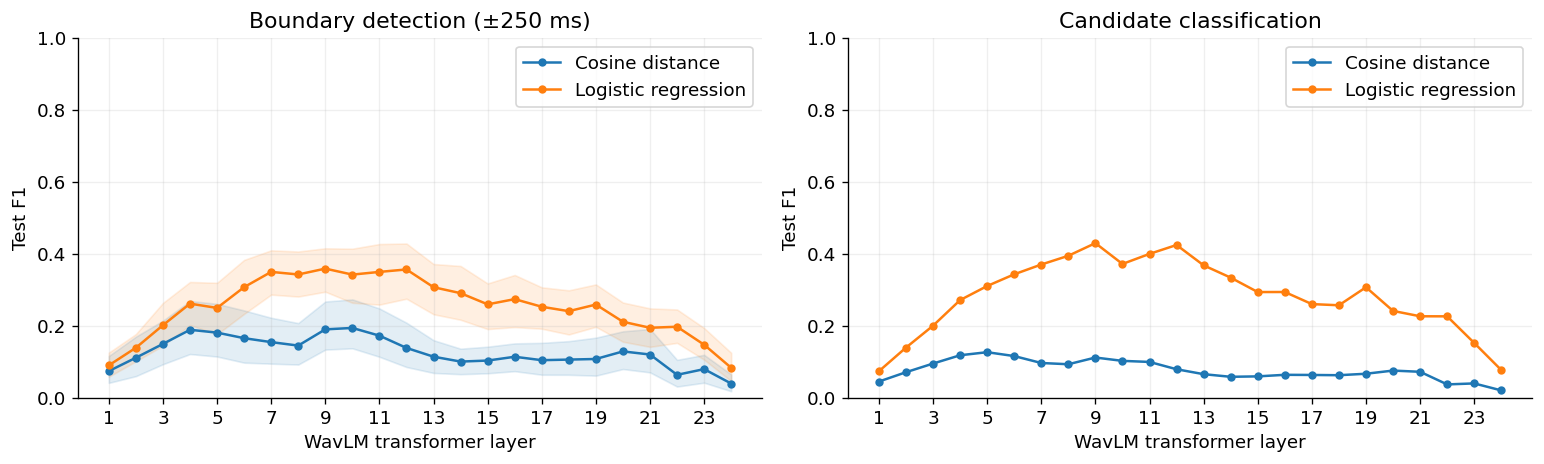

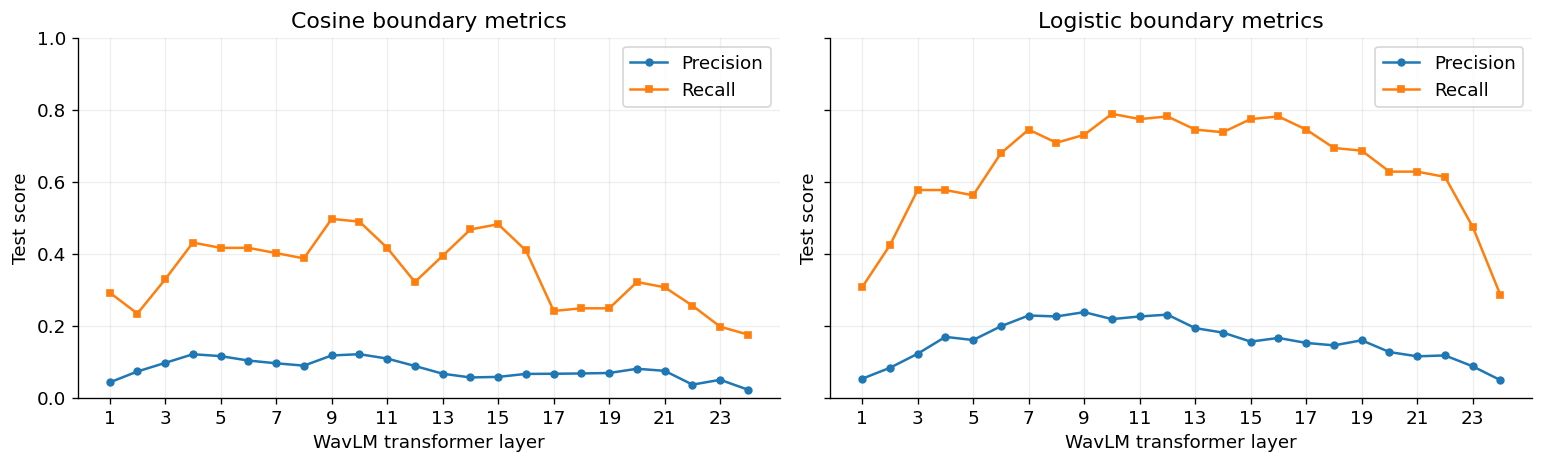

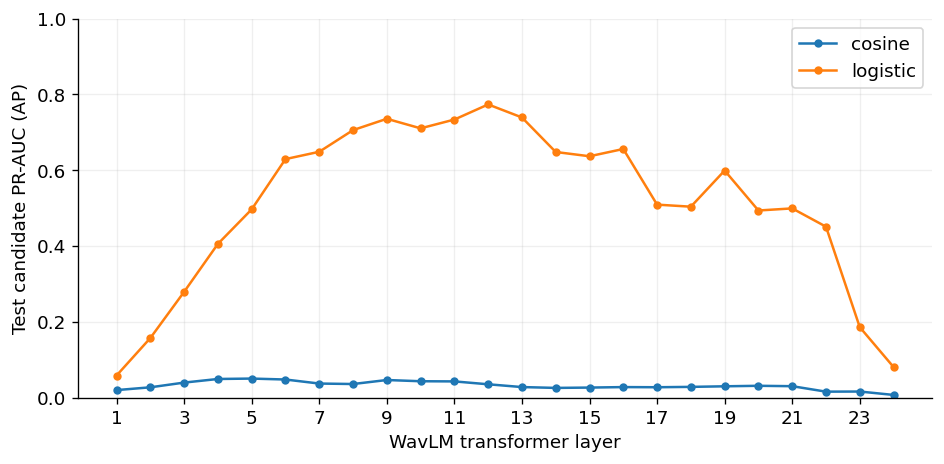

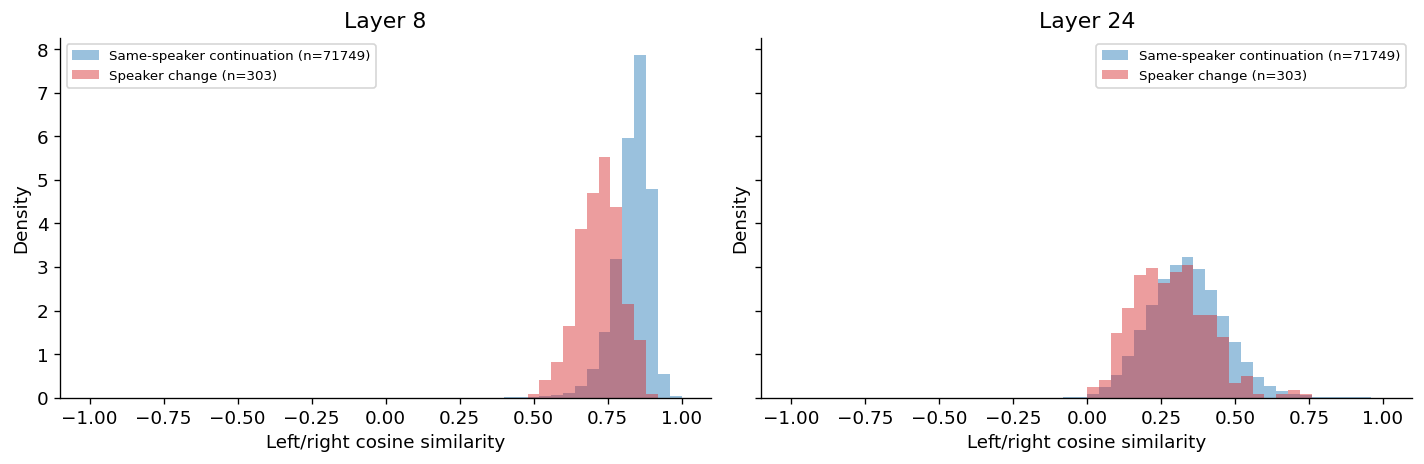

In [25]:
def save_figure(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, bbox_inches="tight")
    plt.show()

fig, axes = plt.subplots(1,2,figsize=(13,4), sharex=True)
for method, name, color in [("cosine","Cosine distance","tab:blue"),("logistic","Logistic regression","tab:orange")]:
    x = RESULTS.layer.to_numpy()
    y = RESULTS[f"{method}_event_f1"].to_numpy()
    axes[0].plot(x,y,"o-",color=color,label=name,ms=4)
    axes[0].fill_between(x,RESULTS[f"{method}_event_f1_ci_low"].to_numpy(float),
                         RESULTS[f"{method}_event_f1_ci_high"].to_numpy(float),color=color,alpha=.12)
    axes[1].plot(x,RESULTS[f"{method}_candidate_f1"],"o-",color=color,label=name,ms=4)
for ax,title in zip(axes,[f"Boundary detection (±{1000*CFG['boundary_tolerance']:.0f} ms)","Candidate classification"]):
    ax.set(xlabel="WavLM transformer layer",ylabel="Test F1",title=title,xticks=range(1,25,2),ylim=(0,1))
    ax.grid(alpha=.2); ax.legend()
save_figure(fig,"layerwise_f1.png")

fig, axes = plt.subplots(1,2,figsize=(13,4),sharey=True)
for ax,method in zip(axes,["cosine","logistic"]):
    for metric,marker in [("precision","o"),("recall","s")]:
        ax.plot(RESULTS.layer,RESULTS[f"{method}_event_{metric}"],marker+"-",label=metric.capitalize(),ms=4)
    ax.set(title=f"{method.capitalize()} boundary metrics",xlabel="WavLM transformer layer",ylabel="Test score",ylim=(0,1),xticks=range(1,25,2))
    ax.grid(alpha=.2); ax.legend()
save_figure(fig,"layerwise_precision_recall.png")

fig,ax = plt.subplots(figsize=(8,4))
for method in ("cosine","logistic"):
    ax.plot(RESULTS.layer,RESULTS[f"{method}_candidate_pr_auc_ap"],"o-",label=method,ms=4)
ax.set(xlabel="WavLM transformer layer",ylabel="Test candidate PR-AUC (AP)",ylim=(0,1),xticks=range(1,25,2))
ax.grid(alpha=.2); ax.legend()
save_figure(fig,"layerwise_pr_auc.png")

TEST_BEST = {method: int(RESULTS.loc[RESULTS[f"{method}_event_f1"].idxmax(),"layer"]) for method in ("cosine","logistic")}
ANALYSIS_LAYER = VALIDATION_BEST["logistic"]
analysis_scores = score_layer(ANALYSIS_LAYER, MANIFEST["splits"]["test"])["logistic"]

fig,axes = plt.subplots(1,2,figsize=(12,4),sharex=True,sharey=True)
for ax,layer in zip(axes,[ANALYSIS_LAYER,24]):
    similarities, labels = [], []
    for rid in MANIFEST["splits"]["test"]:
        y = RECORDS[rid]["labels"]
        keep = y >= 0
        similarities.append(layer_features(rid,layer)[keep,-1]); labels.append(y[keep])
    similarities,labels = np.concatenate(similarities),np.concatenate(labels)
    for value,name,color in [(0,"Same-speaker continuation","tab:blue"),(1,"Speaker change","tab:red")]:
        group = similarities[labels == value]
        if len(group):
            ax.hist(group,bins=np.linspace(-1,1,51),density=True,alpha=.45,label=f"{name} (n={len(group)})",color=color)
    ax.set(title=f"Layer {layer}",xlabel="Left/right cosine similarity",ylabel="Density")
    ax.legend(fontsize=8)
save_figure(fig,"cosine_similarity_distributions.png")

## Detection examples and errors

Visualize matched, missed, and false speaker-change predictions.


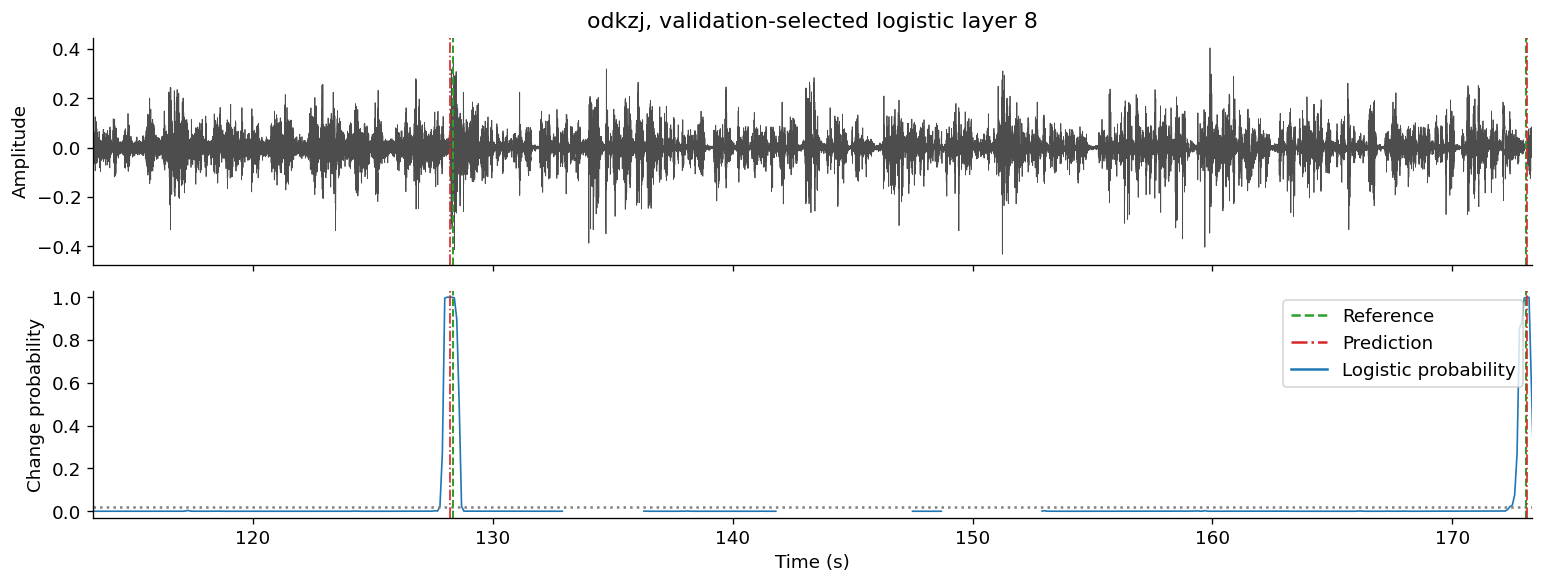

**Correct detection — odkzj, 128.34 s.** A prediction matches one reference within the tolerance; neighboring events still require separate matches.

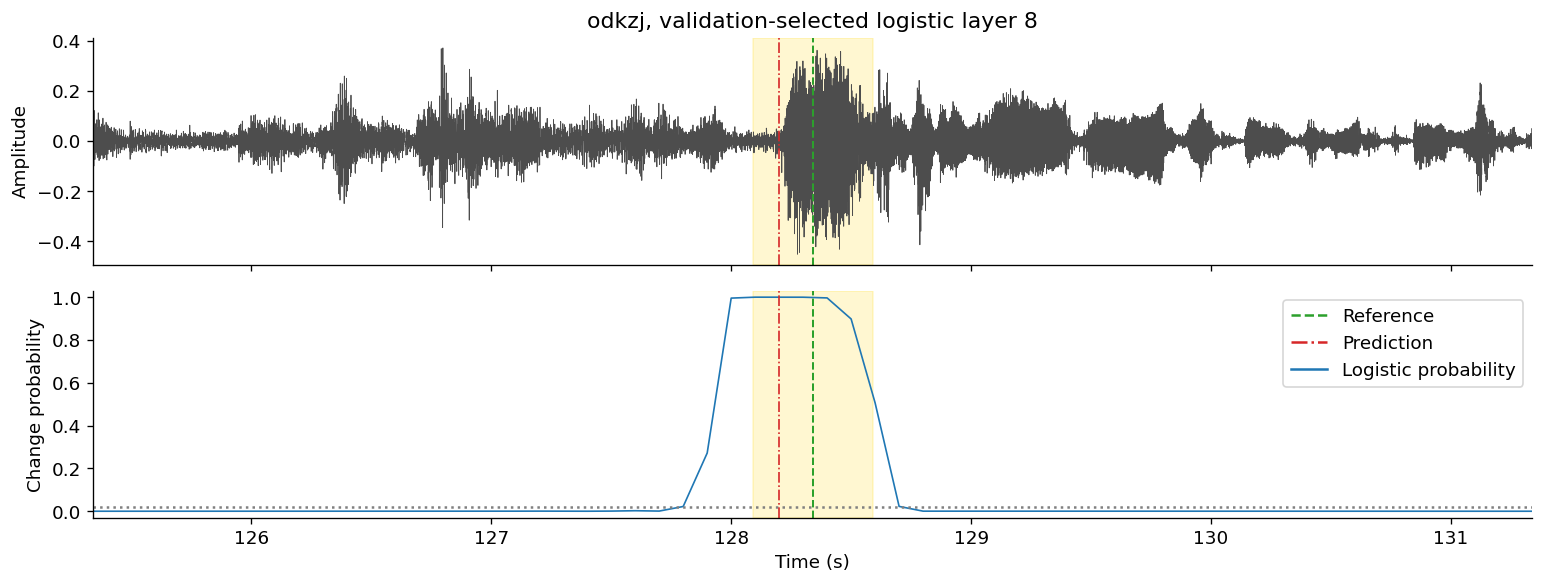

**Missed change — tiams, 34.26 s.** No prediction was matched to this eligible reference under the fixed validation configuration.

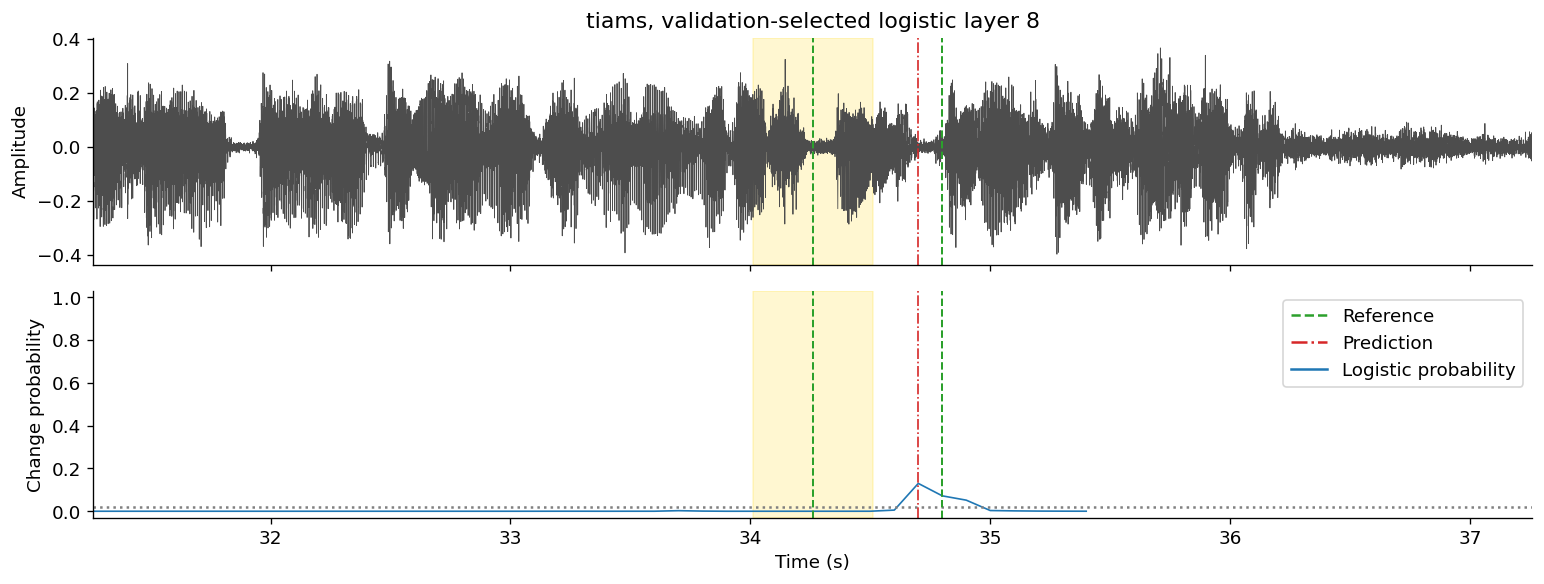

**False positive — gqbvk, 69.50 s.** This prediction has no unmatched eligible reference within the tolerance; listening can suggest follow-up checks.

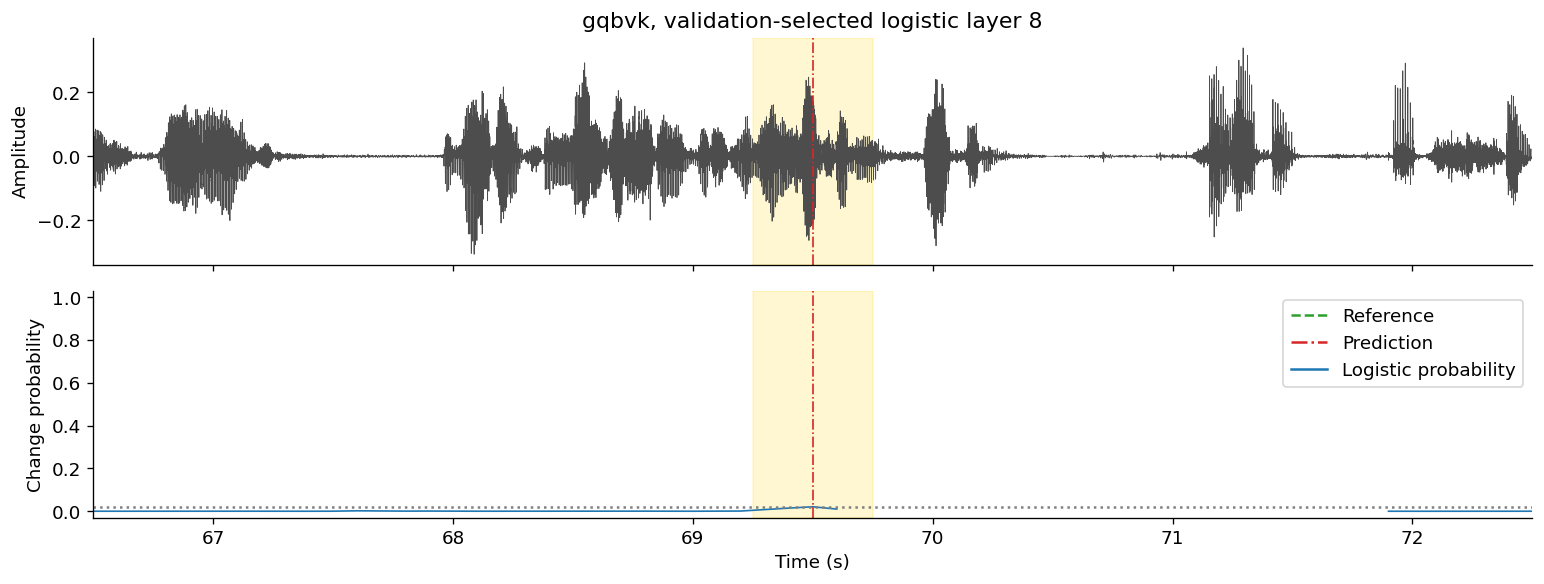

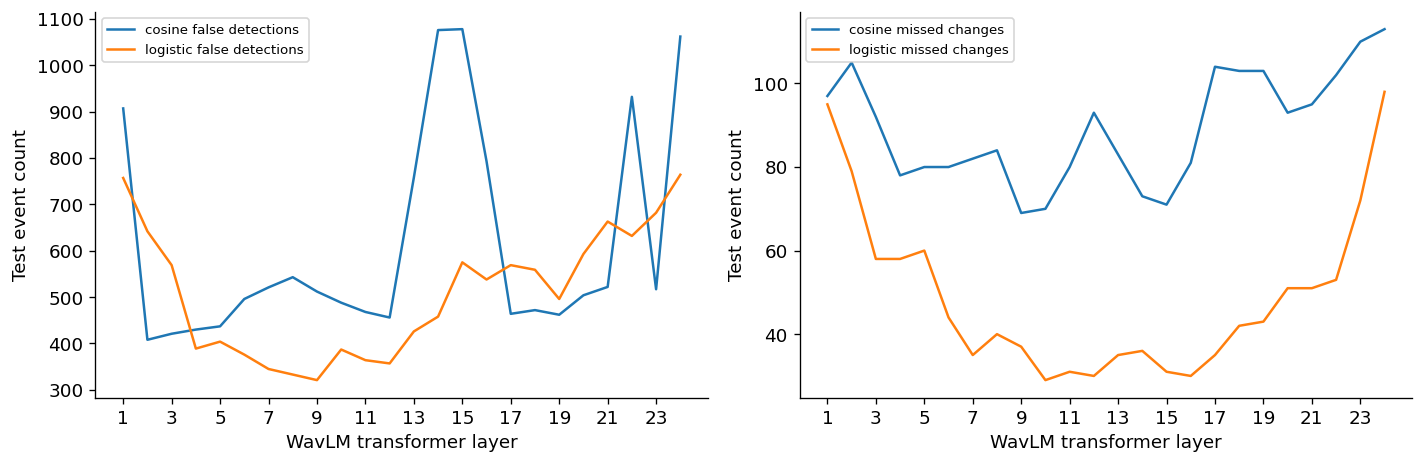

**cosine, validation-selected layer 10: candidate confusion matrix** (rows=true, columns=predicted; order 0,1)

,predicted same,predicted change
true same,70028,1721
true change,194,109


**logistic, validation-selected layer 8: candidate confusion matrix** (rows=true, columns=predicted; order 0,1)

,predicted same,predicted change
true same,71078,671
true change,64,239


In [26]:
def plot_prediction_timeline(rid, layer, scores, start=0.0, end=None, focus=None):
    record = RECORDS[rid]
    end = record["duration"] if end is None else min(record["duration"],end)
    y = load_audio(record["path"], record["duration"], CFG["sample_rate"])
    a,b = int(start*CFG["sample_rate"]), int(end*CFG["sample_rate"])
    step = max(1,(b-a)//30000)
    fig,axes = plt.subplots(2,1,figsize=(13,5),sharex=True)
    axes[0].plot(np.arange(a,b,step)/CFG["sample_rate"],y[a:b:step],lw=.5,color="0.3")
    settings = DETECTION_CONFIGS[("logistic",layer)]
    details = EVENT_DETAILS[("logistic",layer)][rid]
    # Plot separate contiguous grid runs; do not draw lines through masked gaps.
    times = record["times"]
    cuts = np.r_[0,np.flatnonzero(np.diff(times)>CFG["candidate_stride"]*1.5)+1,len(times)]
    for left,right in zip(cuts[:-1],cuts[1:]):
        axes[1].plot(times[left:right],scores[left:right],color="tab:blue",lw=1)
    if np.isfinite(settings["threshold"]):
        axes[1].axhline(settings["threshold"],color="0.5",ls=":",label="Validation threshold")
    for ax in axes:
        for index,t in enumerate(record["refs"]):
            if start <= t <= end:
                ax.axvline(t,color="tab:green",ls="--",lw=1.2,label="Reference" if index == 0 else None)
        for index,t in enumerate(details["predictions"]):
            if start <= t <= end:
                ax.axvline(t,color="tab:red",ls="-.",lw=1,label="Prediction" if index == 0 else None)
        if focus is not None:
            ax.axvspan(max(start,focus-CFG["boundary_tolerance"]),min(end,focus+CFG["boundary_tolerance"]),color="gold",alpha=.18)
    axes[0].set(title=f"{rid}, validation-selected logistic layer {layer}",ylabel="Amplitude")
    axes[1].set(xlabel="Time (s)",ylabel="Change probability",ylim=(-.03,1.03),xlim=(start,end))
    from matplotlib.lines import Line2D
    axes[1].legend(handles=[Line2D([0],[0],color="tab:green",ls="--",label="Reference"),
                            Line2D([0],[0],color="tab:red",ls="-.",label="Prediction"),
                            Line2D([0],[0],color="tab:blue",label="Logistic probability")],loc="upper right")
    fig.tight_layout()
    return fig, y[a:b]

timeline_id = next((rid for rid in MANIFEST["splits"]["test"] if len(RECORDS[rid]["refs"])), MANIFEST["splits"]["test"][0])
timeline_start = max(0,float(RECORDS[timeline_id]["refs"][0])-15) if len(RECORDS[timeline_id]["refs"]) else 0
fig,_ = plot_prediction_timeline(timeline_id,ANALYSIS_LAYER,analysis_scores[timeline_id],start=timeline_start,end=timeline_start+60)
save_figure(fig,"speaker_change_timeline.png")

outcomes = [
    ("Correct detection", "matches", "A prediction matches one reference within the tolerance; neighboring events still require separate matches."),
    ("Missed change", "misses", "No prediction was matched to this eligible reference under the fixed validation configuration."),
    ("False positive", "false_positives", "This prediction has no unmatched eligible reference within the tolerance; listening can suggest follow-up checks."),
]
for title,key,explanation in outcomes:
    example = None
    for rid in MANIFEST["splits"]["test"]:
        values = EVENT_DETAILS[("logistic",ANALYSIS_LAYER)][rid][key]
        if len(values):
            example = (rid, values[0][1] if key == "matches" else values[0])
            break
    if example is None:
        display(Markdown(f"**{title}:** no example in this test subset."))
        continue
    rid,t = example
    start,end = max(0,t-3),min(RECORDS[rid]["duration"],t+3)
    display(Markdown(f"**{title} — {rid}, {t:.2f} s.** {explanation}"))
    fig,audio = plot_prediction_timeline(rid,ANALYSIS_LAYER,analysis_scores[rid],start,end,focus=t)
    save_figure(fig,f"failure_analysis_{key}.png")
    display(Audio(audio,rate=CFG["sample_rate"]))

fig,axes = plt.subplots(1,2,figsize=(12,4))
for method in ("cosine","logistic"):
    axes[0].plot(RESULTS.layer,RESULTS[f"{method}_event_fp"],label=f"{method} false detections")
    axes[1].plot(RESULTS.layer,RESULTS[f"{method}_event_fn"],label=f"{method} missed changes")
for ax in axes:
    ax.set(xlabel="WavLM transformer layer",ylabel="Test event count",xticks=range(1,25,2)); ax.legend(fontsize=8)
save_figure(fig,"failure_analysis.png")
for method in ("cosine","logistic"):
    row = RESULTS[RESULTS.layer == VALIDATION_BEST[method]].iloc[0]
    matrix = np.array([[row[f"{method}_candidate_tn"],row[f"{method}_candidate_fp"]],
                       [row[f"{method}_candidate_fn"],row[f"{method}_candidate_tp"]]],dtype=int)
    display(Markdown(f"**{method}, validation-selected layer {VALIDATION_BEST[method]}: candidate confusion matrix** (rows=true, columns=predicted; order 0,1)"))
    display(pd.DataFrame(matrix,index=["true same","true change"],columns=["predicted same","predicted change"]))

## Experiment findings

Summarize the selected systems, bootstrap comparisons, and error cases.


In [27]:
def paired_bootstrap_difference(first, final, ids, replicates, seed):
    def counts(details):
        return np.asarray([[details[rid]["tp"],details[rid]["fp"],details[rid]["fn"]] for rid in ids],dtype=float)
    a,b = counts(first),counts(final)
    if not len(ids) or not (a[:,[0,2]].sum()):
        return (np.nan,np.nan)
    draws = np.random.default_rng(seed).integers(0,len(ids),size=(replicates,len(ids)))
    def f1(values):
        values = values[draws].sum(axis=1)
        d = 2*values[:,0]+values[:,1]+values[:,2]
        return np.divide(2*values[:,0],d,out=np.zeros(replicates),where=d>0)
    return tuple(np.quantile(f1(a)-f1(b),[.025,.975]))

report = [f"### Observed results ({MODE}; {MANIFEST['protocol']})"]
if CENSUS[CENSUS.split == "test"].evaluated_changes.sum() == 0:
    report.append("**No eligible test reference changes: layer comparisons are not informative. Increase the sample.**")
if len(np.unique(Y_TRAIN)) < 2:
    report.append("**Single-class training: logistic results use constant detectors and cannot test the hypotheses.**")
if CENSUS[CENSUS.split == "val"].evaluated_changes.sum() == 0:
    report.append("**No eligible validation changes: thresholds use the no-detection fallback and selected layers are arbitrary ties. Increase the sample.**")
for method in ("cosine","logistic"):
    winner,selected = TEST_BEST[method],VALIDATION_BEST[method]
    column = f"{method}_event_f1"
    by_layer = RESULTS.set_index("layer")
    best_f1,final_f1,selected_f1 = (float(by_layer.loc[layer,column]) for layer in (winner,24,selected))
    delta = best_f1-final_f1
    ties = by_layer.index[np.isclose(by_layer[column],best_f1,rtol=0,atol=1e-12)].tolist()
    relative = f"{100*delta/final_f1:.1f}%" if final_f1 > 0 else "undefined (layer 24 F1=0)"
    intermediate = by_layer.loc[range(2,24),column]
    intermediate_layer = int(intermediate.idxmax())
    intermediate_delta = float(intermediate.max()-final_f1)
    width = float(by_layer[column].max()-by_layer[column].min())
    low,high = paired_bootstrap_difference(EVENT_DETAILS[(method,selected)],EVENT_DETAILS[(method,24)],
                                           MANIFEST["splits"]["test"],CFG["bootstrap_replicates"],CFG["seed"])
    ap_column = f"{method}_candidate_pr_auc_ap"
    ap_layer = int(RESULTS.loc[RESULTS[ap_column].idxmax(),"layer"]) if RESULTS[ap_column].notna().any() else None
    candidate_layer = int(RESULTS.loc[RESULTS[f"{method}_candidate_f1"].idxmax(),"layer"])
    report.append(
        f"* **{method.capitalize()}:** descriptive test boundary-F1 winner layer **{winner}**, F1={best_f1:.3f}; "
        f"tied best layers={ties} (lowest layer displayed). Layer 24={final_f1:.3f}. Absolute improvement={delta:.3f}; relative={relative}. "
        f"Validation-selected layer **{selected}** has test F1={selected_f1:.3f}; its difference vs layer 24 is "
        f"{selected_f1-final_f1:+.3f}, paired recording-bootstrap 95% interval [{low:.3f}, {high:.3f}]. "
        f"Best strict intermediate layer (2–23)={intermediate_layer}, difference vs 24={intermediate_delta:+.3f}. "
        f"Across-layer F1 range={width:.3f}. Candidate-F1 winner={candidate_layer}; AP winner={ap_layer}.")
    report.append(f"  H1 descriptive evidence: {'an intermediate layer exceeds' if intermediate_delta > 0 else 'no intermediate layer exceeds'} layer 24 on this sample. "
                  "No significance or generalization claim follows from this comparison.")
agreement = TEST_BEST["cosine"] == TEST_BEST["logistic"]
report.append(f"* Cosine and logistic detectors {'agree' if agreement else 'differ'} on the descriptive best test boundary-F1 layer: {TEST_BEST}.")
report.append("* H2 is assessed by the metric-specific winners above. H3 is assessed through the similarity distributions and probe metrics; nuisance acoustic factors remain uncontrolled.")
report.append("* The observed F1 ranges quantify variation across layers; whether that variation is substantial requires larger, independent replications. Bootstrap bands are descriptive and do not correct for layer selection.")
report.append("* Limitations: small/correlated samples, oracle speech filtering, excluded overlap and silence, prefix cropping, noncausal chunk context, unknown speaker/source leakage, and a fixed linear-probe design. No accent or language invariance is established.")
report.append("* Follow up with official held-out data, repeated development splits, verified speaker/source isolation, VAD/overlap-aware evaluation, causal/context sensitivity tests, and separately annotated multilingual/accent-controlled corpora.")
report_text = "\n\n".join(report)
display(Markdown(report_text))
(OUT / "conclusions.md").write_text(report_text)

prediction_rows = []
for method in ("cosine","logistic"):
    layer = TEST_BEST[method]
    scores = score_layer(layer,MANIFEST["splits"]["test"])[method]
    settings = DETECTION_CONFIGS[(method,layer)]
    for rid in MANIFEST["splits"]["test"]:
        detected = EVENT_DETAILS[(method,layer)][rid]["predictions"]
        matched_predictions = {p for p,r in EVENT_DETAILS[(method,layer)][rid]["matches"]}
        for t,label,score in zip(RECORDS[rid]["times"],RECORDS[rid]["labels"],scores[rid]):
            is_detection = bool(np.any(np.isclose(detected,t,atol=1e-8,rtol=0)))
            prediction_rows.append({"recording":rid,"method":method,"layer":layer,"time_seconds":t,
                                    "label":int(label),"score":float(score),"threshold":settings["threshold"],
                                    "predicted_boundary":is_detection,"matched_reference":float(t) in matched_predictions,
                                    "layer_selection":"descriptive-test-winner"})
pd.DataFrame(prediction_rows).to_csv(OUT / "best_layer_predictions.csv",index=False)
save_json(OUT / "reference_boundaries.json", {rid: {"evaluated":r["refs"],"all_clean":r["raw_refs"],"exposure":r["exposure"]}
                                             for rid,r in RECORDS.items()})
print("Outputs:", sorted(p.name for p in OUT.iterdir()))

### Observed results (pilot; development-three-way-pilot)

* **Cosine:** descriptive test boundary-F1 winner layer **10**, F1=0.194; tied best layers=[10] (lowest layer displayed). Layer 24=0.039. Absolute improvement=0.154; relative=393.4%. Validation-selected layer **10** has test F1=0.194; its difference vs layer 24 is +0.154, paired recording-bootstrap 95% interval [0.106, 0.219]. Best strict intermediate layer (2–23)=10, difference vs 24=+0.154. Across-layer F1 range=0.154. Candidate-F1 winner=5; AP winner=5.

  H1 descriptive evidence: an intermediate layer exceeds layer 24 on this sample. No significance or generalization claim follows from this comparison.

* **Logistic:** descriptive test boundary-F1 winner layer **9**, F1=0.358; tied best layers=[9] (lowest layer displayed). Layer 24=0.083. Absolute improvement=0.275; relative=331.9%. Validation-selected layer **8** has test F1=0.342; its difference vs layer 24 is +0.259, paired recording-bootstrap 95% interval [0.209, 0.309]. Best strict intermediate layer (2–23)=9, difference vs 24=+0.275. Across-layer F1 range=0.275. Candidate-F1 winner=9; AP winner=12.

  H1 descriptive evidence: an intermediate layer exceeds layer 24 on this sample. No significance or generalization claim follows from this comparison.

* Cosine and logistic detectors differ on the descriptive best test boundary-F1 layer: {'cosine': 10, 'logistic': 9}.

* H2 is assessed by the metric-specific winners above. H3 is assessed through the similarity distributions and probe metrics; nuisance acoustic factors remain uncontrolled.

* The observed F1 ranges quantify variation across layers; whether that variation is substantial requires larger, independent replications. Bootstrap bands are descriptive and do not correct for layer selection.

* Limitations: small/correlated samples, oracle speech filtering, excluded overlap and silence, prefix cropping, noncausal chunk context, unknown speaker/source leakage, and a fixed linear-probe design. No accent or language invariance is established.

* Follow up with official held-out data, repeated development splits, verified speaker/source isolation, VAD/overlap-aware evaluation, causal/context sensitivity tests, and separately annotated multilingual/accent-controlled corpora.

Outputs: ['audio_download_sources.json', 'audio_input_manifest.json', 'best_layer_predictions.csv', 'conclusions.md', 'cosine_similarity_distributions.png', 'dataset_census.csv', 'dataset_summary.json', 'environment.json', 'event_details.json', 'experiment_config.json', 'failure_analysis.png', 'failure_analysis_false_positives.png', 'failure_analysis_matches.png', 'failure_analysis_misses.png', 'feature_manifest.json', 'layerwise_f1.png', 'layerwise_pr_auc.png', 'layerwise_precision_recall.png', 'layerwise_results.csv', 'layerwise_results.json', 'logistic_layer_01.joblib', 'logistic_layer_01_parameters.npz', 'logistic_layer_02.joblib', 'logistic_layer_02_parameters.npz', 'logistic_layer_03.joblib', 'logistic_layer_03_parameters.npz', 'logistic_layer_04.joblib', 'logistic_layer_04_parameters.npz', 'logistic_layer_05.joblib', 'logistic_layer_05_parameters.npz', 'logistic_layer_06.joblib', 'logistic_layer_06_parameters.npz', 'logistic_layer_07.joblib', 'logistic_layer_07_parameters.npz', 

## Exported results and checks

Archive figures and metrics and run implementation sanity checks.


In [28]:
archive_path = shutil.make_archive(str(OUT.parent / f"wavlm_scd_{MODE}_results"), "zip", OUT)
print("Results archive:", archive_path)
try:
    from google.colab import files
    files.download(archive_path)
except ImportError:
    from IPython.display import FileLink
    display(FileLink(archive_path))

Results archive: /content/drive/MyDrive/wavlm_layerwise_scd/results/wavlm_scd_pilot_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [29]:
def run_cpu_sanity_checks():
    text = """SPEAKER toy 1 0.0 1.0 <NA> <NA> A <NA> <NA>
SPEAKER toy 1 1.0 1.0 <NA> <NA> A <NA> <NA>
SPEAKER toy 1 2.1 1.9 <NA> <NA> B <NA> <NA>
SPEAKER toy 1 5.0 1.0 <NA> <NA> C <NA> <NA>"""
    turns = parse_rttm_text(text,"toy")
    assert len(turns) == 4 and turns[2].end == 4.0
    spans = active_intervals(turns,6.0)
    np.testing.assert_allclose(clean_change_boundaries(spans,.2),[2.05])
    overlap = parse_rttm_text("SPEAKER x 1 0 2 <NA> <NA> A <NA> <NA>\nSPEAKER x 1 1 2 <NA> <NA> B <NA> <NA>")
    assert not len(clean_change_boundaries(active_intervals(overlap,3),.2))
    cfg = {**CFG,"context_seconds":.5,"candidate_stride":.1,"label_tolerance":.1}
    times,labels,refs,exposure = make_candidates(spans,np.array([2.05]),6,cfg)
    assert np.any(labels==1) and np.any(labels==0)
    assert all(context_properties(spans,t,.5)[2] is False for t in times)
    same = active_intervals([Turn("s",0,4,"A")],4)
    _,same_labels,_,_ = make_candidates(same,np.empty(0),4,cfg)
    assert np.all(same_labels == 0)
    from types import SimpleNamespace
    hidden = tuple(torch.full((1,20,3),float(i)) for i in range(25))
    layers = transformer_hidden_states(SimpleNamespace(hidden_states=hidden),24,3)
    assert layers[0][0,0,0] == 1 and layers[-1][0,0,0] == 24
    kernels,strides = [10,3,3,3,3,2,2],[5,2,2,2,2,2,2]
    assert convolution_geometry(kernels,strides) == (400,320)
    centers = frame_centers(100,3200,kernels,strides,16000)
    np.testing.assert_allclose(centers[:2],[.21246875,.23246875])
    centers = np.arange(20,dtype=float)*.1+.05
    h = torch.arange(20,dtype=torch.float32).reshape(1,20,1).repeat(1,1,3)
    pooled = pool_candidate_features([h],centers,np.array([1.0]),.5)
    np.testing.assert_allclose(pooled[0,0,:3],5,atol=1e-3)
    grid = np.arange(1,29,.1)
    assigned = np.zeros(len(grid),int)
    for ca,cb,start,end in chunk_plan(30*16000,16000,12,2,320):
        chosen = (grid >= ca) & (grid < cb)
        assigned[chosen] += 1
        if chosen.any():
            assert (grid[chosen]-1 >= start/16000).all()
            assert (grid[chosen]+1 <= end/16000+1e-8).all()
    assert np.all(assigned==1)
    splits = make_split_manifest([f"d{i}" for i in range(20)],["z"],{**CFG,"mode":"smoke","max_recordings":{"train":5,"val":2,"test":2}})
    assert not set(splits["splits"]["train"]) & set(splits["splits"]["test"])
    matches,fp,fn = match_boundaries([.15,.35],[0,.2],.2)
    assert len(matches)==2 and not fp and not fn
    matches,fp,fn = match_boundaries([1,1.1],[1],.25)
    assert len(matches)==1 and len(fp)==1 and not fn
    assert precision_recall_f1(2,1,1) == {"precision":2/3,"recall":2/3,"f1":2/3}
    assert precision_recall_f1(0,0,0)["f1"] == 0
    metrics = candidate_metrics(np.array([0,1,1]),np.array([.1,.8,.2]),.5)
    assert (metrics["tn"],metrics["fp"],metrics["fn"],metrics["tp"]) == (1,0,1,1)
    assert np.isnan(candidate_metrics(np.array([0]),np.array([.1]),.5)["pr_auc_ap"])
    np.testing.assert_allclose(detect_boundaries([1,1.1,2],[.8,.9,.7],.6,.25),[1.1,2])
    assert not len(detect_boundaries([1],[.9],float("inf"),.25))
    print("CPU sanity checks passed: RTTM, same speaker/overlap/silence, labels, layer indices, timing, splits, pooling, NMS, one-to-one matching, metrics.")

run_cpu_sanity_checks()

CPU sanity checks passed: RTTM, same speaker/overlap/silence, labels, layer indices, timing, splits, pooling, NMS, one-to-one matching, metrics.
